# Лабораторная работа №1
## Анализ и прогнозирование временных рядов на примере розничных продаж

**Данные:** `retail_sales_mock_data.csv` — месячные розничные продажи (янв. 2020 – дек. 2023, 48 наблюдений) и два бинарных признака: `Promotion` (акция в месяце) и `HolidayMonth` (праздничный месяц — только декабрь).

**План:**
1. Разведочный анализ (EDA) и декомпозиция тремя методами (классическая/STL, FFT, вейвлеты)
2. Построение ARIMA и SARIMAX
3. Оценка качества (MSE, R², AIC, BIC, анализ остатков)
4. Документирование и интерпретация (комментарии в коде + выводы после каждого этапа)

In [1]:
import warnings
warnings.filterwarnings('ignore')            # статсмодели генерируют много предупреждений при переборе параметров

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pywt                                    # вейвлет-анализ
from scipy import stats, signal

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

warnings.simplefilter('ignore')               # statsmodels включает свои фильтры при импорте — отключаем повторно
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (11, 4)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

## 0. Загрузка и первичный осмотр данных

In [2]:
# Читаем CSV, индексируем по дате и явно задаём месячную частоту 'MS' (начало месяца),
# это нужно statsmodels для корректной работы с сезонностью и прогнозом.
df = pd.read_csv('retail_sales_mock_data.csv', parse_dates=['Date'], index_col='Date').asfreq('MS')
y = df['SalesAmount'].astype(float)
X = df[['Promotion', 'HolidayMonth']].astype(float)

print('Размер:', df.shape, '| период:', df.index.min().date(), '-', df.index.max().date(), '| частота:', df.index.freqstr)
print('Пропусков:', int(df.isna().sum().sum()), '| дубликатов дат:', int(df.index.duplicated().sum()))
display(df.head(13))
display(df.describe().T)
print('Праздничные месяцы:', list(df.index[df.HolidayMonth == 1].strftime('%Y-%m')))
print('Месяцы с акцией   :', list(df.index[df.Promotion == 1].strftime('%Y-%m')))

Размер: (48, 3) | период: 2020-01-01 - 2023-12-01 | частота: MS
Пропусков: 0 | дубликатов дат: 0


,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0
2020-06-01,9131,1,0
2020-07-01,9089,0,0
2020-08-01,10300,0,0
2020-09-01,10464,0,0


,count,mean,std,min,25%,50%,75%,max
SalesAmount,48.000,"11,768.542","2,257.545","7,783.000","10,219.750","11,851.000","13,014.000","17,996.000"
Promotion,48.000,0.125,0.334,0.000,0.000,0.000,0.000,1.000
HolidayMonth,48.000,0.083,0.279,0.000,0.000,0.000,0.000,1.000


Праздничные месяцы: ['2020-12', '2021-12', '2022-12', '2023-12']
Месяцы с акцией   : ['2020-04', '2020-06', '2020-10', '2021-05', '2022-01', '2023-05']


# 2.1. Разведочный анализ данных (EDA)

### 2.1.1. Визуализации разных типов

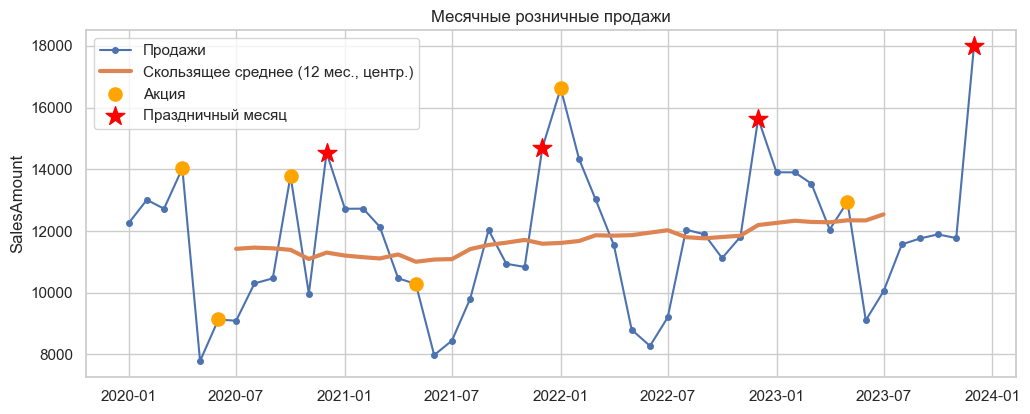

In [3]:
# 1) Линейный график + скользящее среднее (12 мес.) + отметки акций и праздников
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(y, marker='o', ms=4, label='Продажи')
ax.plot(y.rolling(12, center=True).mean(), lw=3, label='Скользящее среднее (12 мес., центр.)')
ax.scatter(y.index[X.Promotion == 1], y[X.Promotion == 1], c='orange', s=90, zorder=5, label='Акция')
ax.scatter(y.index[X.HolidayMonth == 1], y[X.HolidayMonth == 1], c='red', marker='*', s=200, zorder=5, label='Праздничный месяц')
ax.set_title('Месячные розничные продажи'); ax.set_ylabel('SalesAmount'); ax.legend()
plt.show()

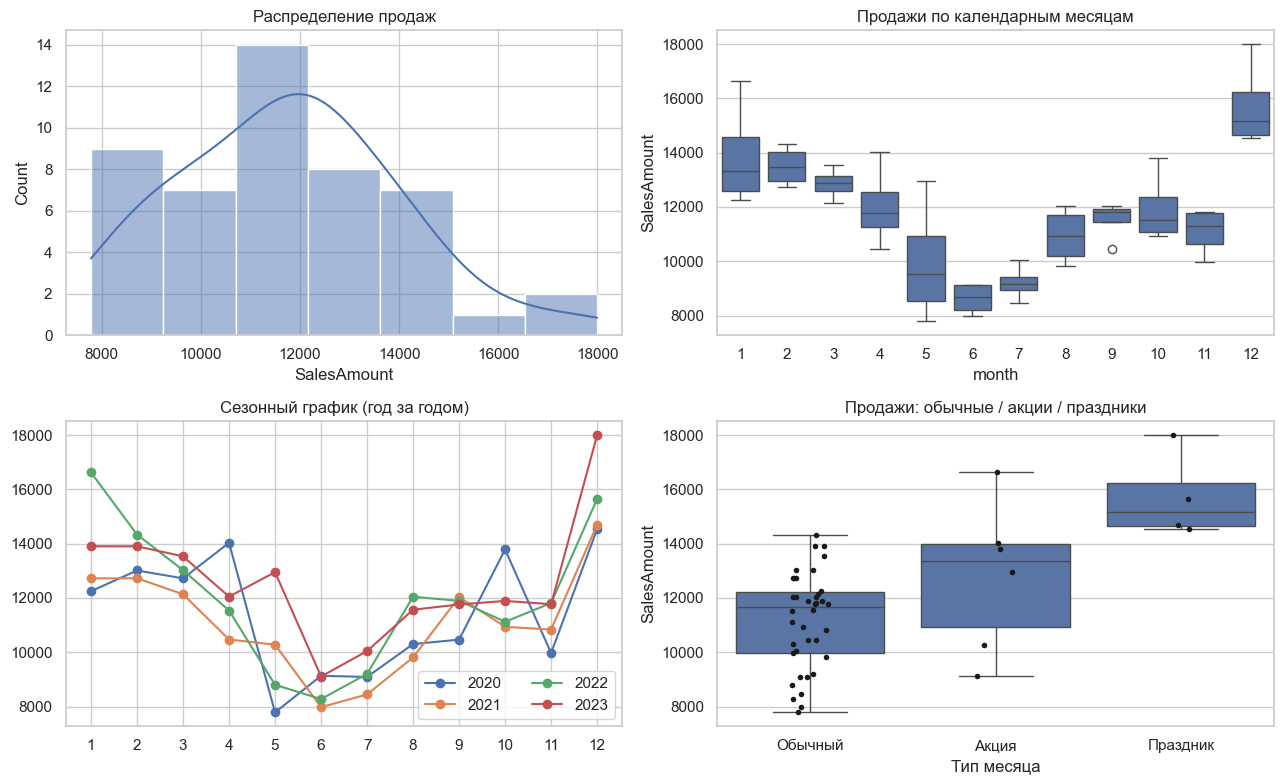

            count       mean       std
Тип месяца                            
Акция           6 12,799.667 2,718.074
Обычный        38 11,190.026 1,751.240
Праздник        4 15,717.750 1,595.927


In [4]:
# 2) Распределение, ящики по месяцам, сезонный график по годам, влияние акций/праздников
tmp = df.copy(); tmp['month'] = tmp.index.month; tmp['year'] = tmp.index.year
fig, axs = plt.subplots(2, 2, figsize=(13, 8))

sns.histplot(y, kde=True, ax=axs[0, 0]); axs[0, 0].set_title('Распределение продаж')

sns.boxplot(data=tmp, x='month', y='SalesAmount', ax=axs[0, 1]); axs[0, 1].set_title('Продажи по календарным месяцам')

for yr, g in tmp.groupby('year'):
    axs[1, 0].plot(g['month'], g['SalesAmount'], marker='o', label=str(yr))
axs[1, 0].set_title('Сезонный график (год за годом)'); axs[1, 0].set_xticks(range(1, 13)); axs[1, 0].legend(ncol=2)

tmp['Тип месяца'] = np.select([tmp.HolidayMonth == 1, tmp.Promotion == 1], ['Праздник', 'Акция'], 'Обычный')
sns.boxplot(data=tmp, x='Тип месяца', y='SalesAmount', order=['Обычный', 'Акция', 'Праздник'], ax=axs[1, 1])
sns.stripplot(data=tmp, x='Тип месяца', y='SalesAmount', order=['Обычный', 'Акция', 'Праздник'], color='k', size=4, ax=axs[1, 1])
axs[1, 1].set_title('Продажи: обычные / акции / праздники')
plt.tight_layout(); plt.show()

print(tmp.groupby('Тип месяца')['SalesAmount'].agg(['count', 'mean', 'std']))

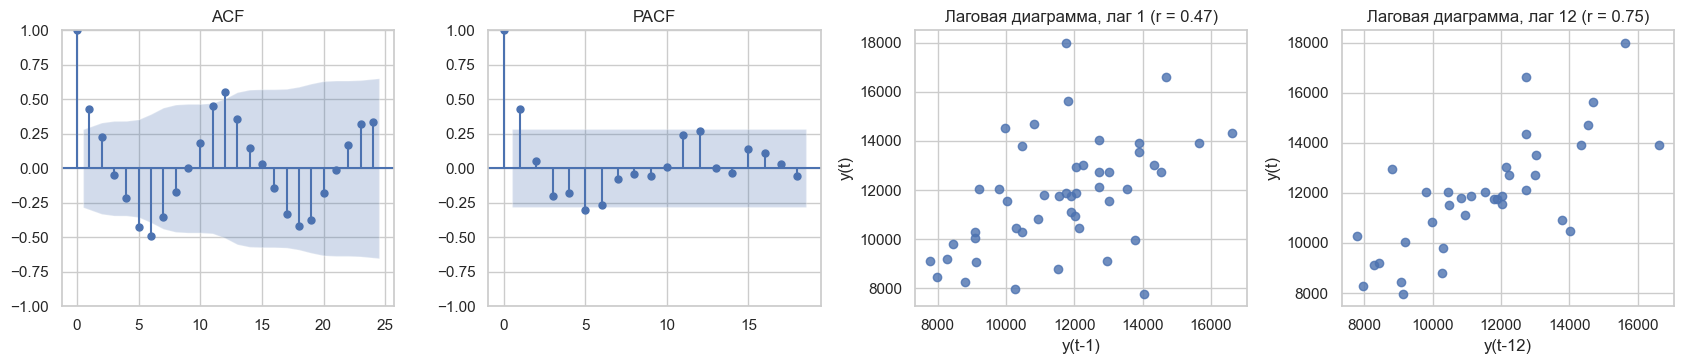

In [5]:
# 3) Автокорреляционная структура: ACF/PACF и лаговые диаграммы
fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
plot_acf(y, lags=24, ax=axs[0]); axs[0].set_title('ACF')
plot_pacf(y, lags=18, ax=axs[1], method='ywm'); axs[1].set_title('PACF')
for ax, lag in zip(axs[2:], [1, 12]):
    ax.scatter(y.shift(lag), y, alpha=.8); ax.set_title(f'Лаговая диаграмма, лаг {lag} (r = {y.autocorr(lag):.2f})')
    ax.set_xlabel(f'y(t-{lag})'); ax.set_ylabel('y(t)')
plt.tight_layout(); plt.show()

In [6]:
# 4) Тесты стационарности: ADF (H0: единичный корень, т.е. нестационарность) и KPSS (H0: стационарность)
def stationarity(s, name):
    adf_p = adfuller(s.dropna(), autolag='AIC')[1]
    kpss_p = kpss(s.dropna(), regression='c', nlags='auto')[1]
    return {'Ряд': name, 'ADF p-value': adf_p, 'KPSS p-value': kpss_p,
            'Вывод': 'стационарен' if (adf_p < .05 and kpss_p >= .05) else 'требуется дифференцирование/проверка'}

st = pd.DataFrame([stationarity(y, 'y (исходный)'),
                   stationarity(y.diff(), 'Δy (d=1)'),
                   stationarity(y.diff(12), 'Δ12 y (D=1, s=12)')])
display(st)

,Ряд,ADF p-value,KPSS p-value,Вывод
0,y (исходный),0.000,0.100,стационарен
1,Δy (d=1),0.000,0.100,стационарен
2,"Δ12 y (D=1, s=12)",0.005,0.100,стационарен


In [7]:
# Базовые факты для обоснования дальнейшего выбора моделей
trend_fit = stats.linregress(np.arange(len(y)), y.values)
print(f'Линейный тренд: {trend_fit.slope:,.1f} ед./мес., p-value = {trend_fit.pvalue:.4f}, R² тренда = {trend_fit.rvalue**2:.3f}')
yearly = y.groupby(y.index.year).mean()
print('Среднегодовые продажи:'); display(yearly.to_frame('mean'))
print('Среднее по месяцам:'); display(y.groupby(y.index.month).mean().round(0).to_frame('mean').T)

Линейный тренд: 32.1 ед./мес., p-value = 0.1755, R² тренда = 0.040
Среднегодовые продажи:


,mean
Date,
2020,"11,422.250"
2021,"11,088.000"
2022,"12,025.333"
2023,"12,538.583"


Среднее по месяцам:


Date,1,2,3,4,5,6,7,8,9,10,11,12
mean,"13,874.000","13,493.000","12,854.000","12,021.000","9,953.000","8,621.000","9,194.000","10,930.000","11,536.000","11,934.000","11,096.000","15,718.000"


### 2.1.2. Метод 1 — классическая (аддитивная и мультипликативная) и STL-декомпозиция

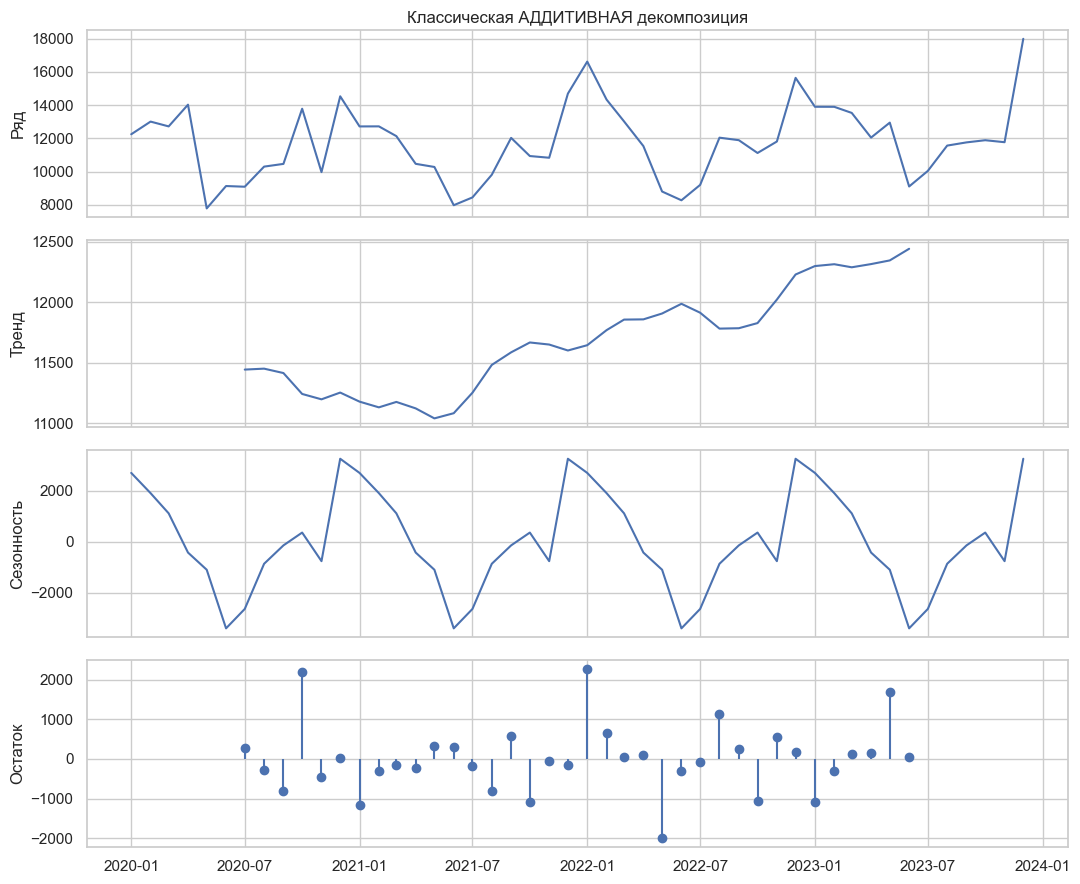

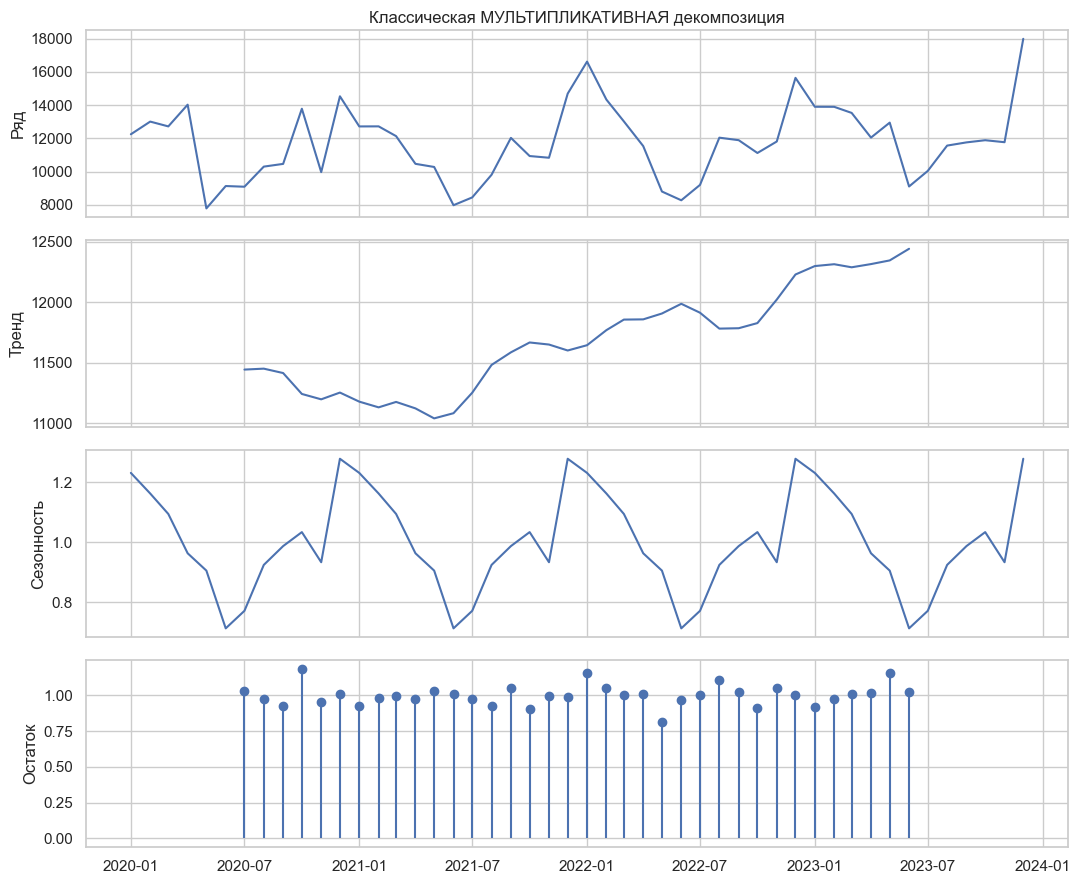

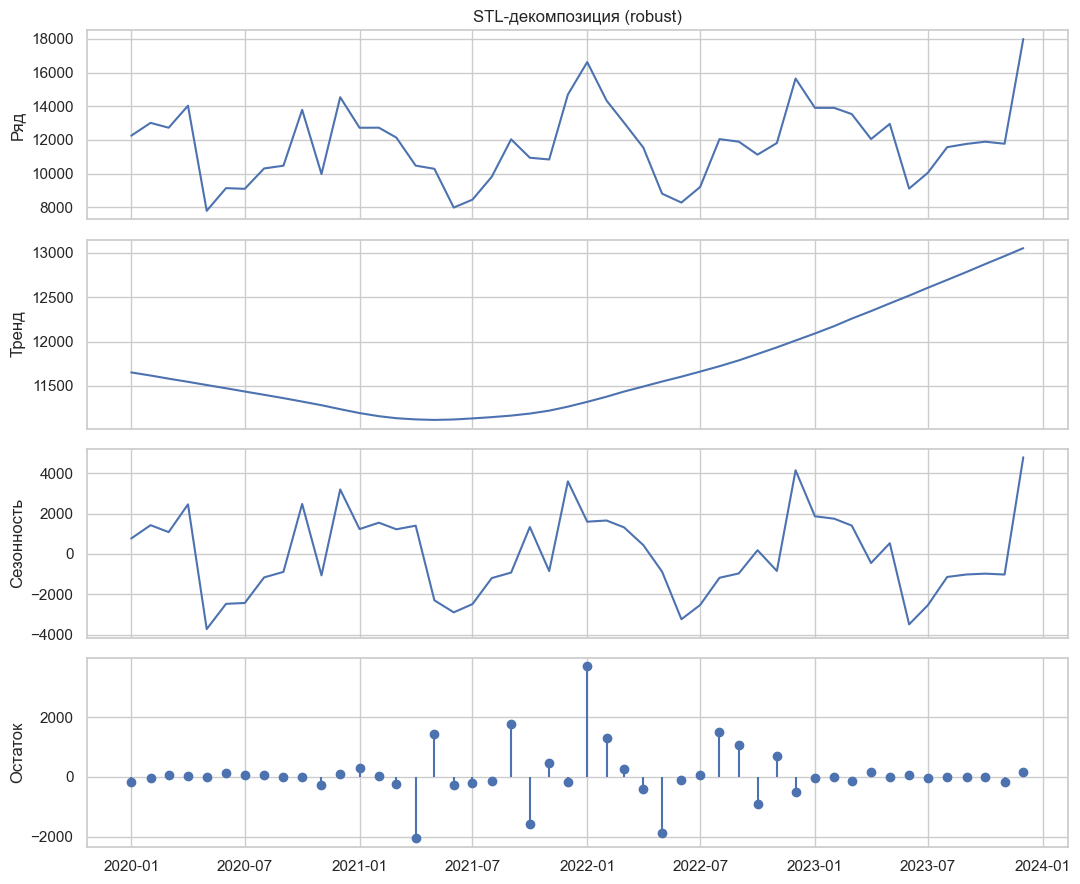

In [8]:
# Период сезонности: данные месячные, годовая сезонность -> 12.
PERIOD = 12
dec_add = seasonal_decompose(y, model='additive', period=PERIOD)
dec_mul = seasonal_decompose(y, model='multiplicative', period=PERIOD)
dec_stl = STL(y, period=PERIOD, robust=True).fit()          # robust=True: устойчива к выбросам (акции)

def plot_dec(trend, seas, resid, title):
    fig, axs = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
    axs[0].plot(y); axs[0].set_ylabel('Ряд')
    axs[1].plot(trend); axs[1].set_ylabel('Тренд')
    axs[2].plot(seas); axs[2].set_ylabel('Сезонность')
    axs[3].stem(resid.index, resid.values, basefmt=' '); axs[3].set_ylabel('Остаток')
    axs[0].set_title(title); plt.tight_layout(); plt.show()

plot_dec(dec_add.trend, dec_add.seasonal, dec_add.resid, 'Классическая АДДИТИВНАЯ декомпозиция')
plot_dec(dec_mul.trend, dec_mul.seasonal, dec_mul.resid, 'Классическая МУЛЬТИПЛИКАТИВНАЯ декомпозиция')
plot_dec(dec_stl.trend, dec_stl.seasonal, dec_stl.resid, 'STL-декомпозиция (robust)')

,Наблюдений в остатке,СКО остатка,Сила сезонности Fs,Ljung-Box p (лаг 10),Shapiro p (норм. остатка)
Аддитивная,36,871.424,0.833,0.609,0.026
Мультипликативная,36,877.144,0.830,0.680,0.025
STL (robust),48,882.671,0.839,0.134,0.000


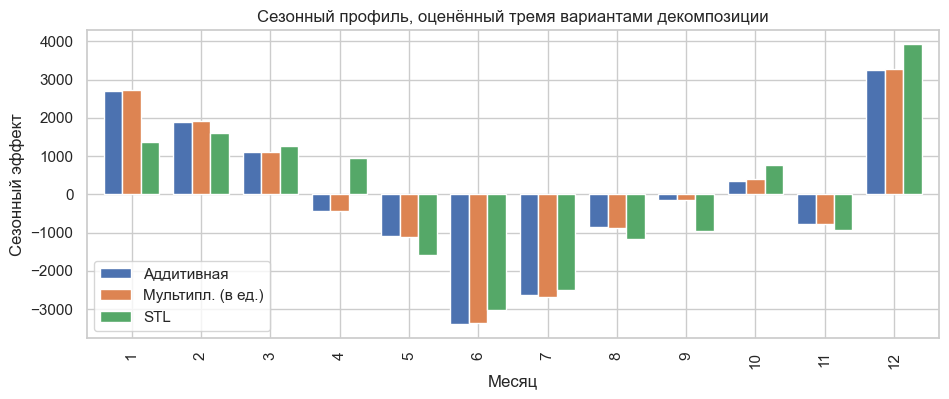

In [9]:
# Количественное сравнение декомпозиций.
# Для сопоставимости остаток мультипликативной модели переводим в абсолютные единицы: R_abs = y - T*S.
def seasonal_strength(resid, seas):
    # сила сезонности по Hyndman: Fs = max(0, 1 - Var(R)/Var(S+R))
    r, s = resid.dropna(), seas.loc[resid.dropna().index]
    return max(0, 1 - r.var() / (r + s).var())

res_add = dec_add.resid.dropna()
res_mul_abs = (y - dec_mul.trend * dec_mul.seasonal).dropna()
res_stl = dec_stl.resid

def lb_p(r, lag=10): return acorr_ljungbox(r, lags=[lag], return_df=True)['lb_pvalue'].iloc[0]

cmp_dec = pd.DataFrame({
    'Наблюдений в остатке': [len(res_add), len(res_mul_abs), len(res_stl)],
    'СКО остатка': [res_add.std(), res_mul_abs.std(), res_stl.std()],
    'Сила сезонности Fs': [seasonal_strength(dec_add.resid, dec_add.seasonal),
                           seasonal_strength(res_mul_abs, dec_mul.seasonal * dec_mul.trend.mean()),
                           seasonal_strength(dec_stl.resid, dec_stl.seasonal)],
    'Ljung-Box p (лаг 10)': [lb_p(res_add), lb_p(res_mul_abs), lb_p(res_stl)],
    'Shapiro p (норм. остатка)': [stats.shapiro(r)[1] for r in (res_add, res_mul_abs, res_stl)],
}, index=['Аддитивная', 'Мультипликативная', 'STL (robust)'])
display(cmp_dec)

# Усреднённый сезонный профиль по трём методам (в абсолютных единицах)
seas_prof = pd.DataFrame({
    'Аддитивная': dec_add.seasonal.iloc[:12].values,
    'Мультипл. (в ед.)': ((dec_mul.seasonal.iloc[:12] - 1) * y.mean()).values,
    'STL': dec_stl.seasonal.groupby(dec_stl.seasonal.index.month).mean().values,
}, index=range(1, 13))
ax = seas_prof.plot(kind='bar', figsize=(11, 4), width=.8); ax.set_xlabel('Месяц'); ax.set_ylabel('Сезонный эффект')
ax.set_title('Сезонный профиль, оценённый тремя вариантами декомпозиции'); plt.show()

In [10]:
# Проверка: меняется ли амплитуда сезонности вместе с уровнем (признак мультипликативности)?
# Если да — корреляция между трендом и размахом сезонности (внутригодовой размах) будет заметной.
rng = y.groupby(y.index.year).agg(lambda s: s.max() - s.min())
lvl = y.groupby(y.index.year).mean()
print(pd.DataFrame({'Средний уровень': lvl, 'Размах внутри года': rng, 'Размах/уровень': rng / lvl}))

      Средний уровень  Размах внутри года  Размах/уровень
Date                                                     
2020       11,422.250           6,751.000           0.591
2021       11,088.000           6,720.000           0.606
2022       12,025.333           8,350.000           0.694
2023       12,538.583           8,892.000           0.709


### 2.1.3. Метод 2 — спектральный анализ (FFT)

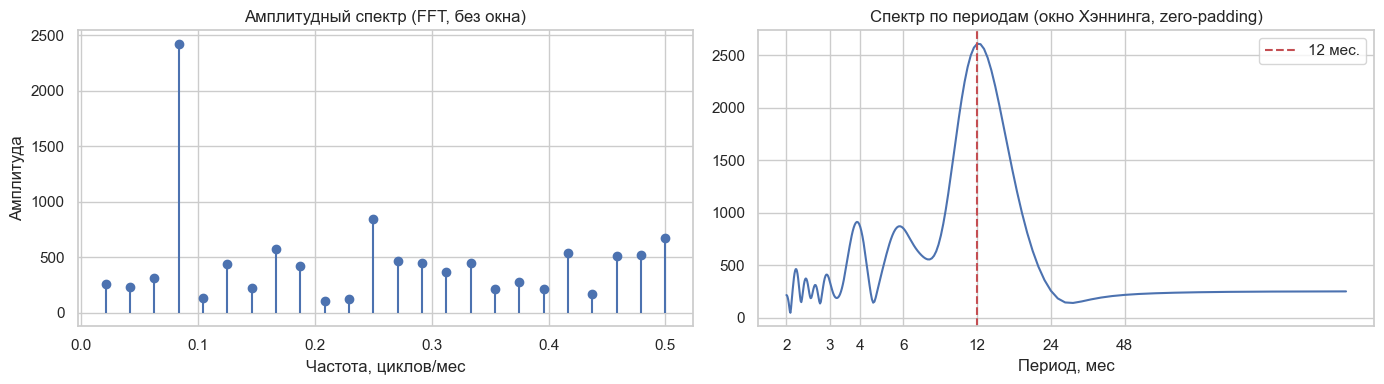

,Частота (цикл/мес),Период (мес),Амплитуда,"Доля энергии, %"
0,0.083,12.000,"2,421.303",59.761
1,0.250,4.000,840.412,7.200
2,0.167,6.000,573.037,3.347
3,0.417,2.400,535.225,2.920
4,0.333,3.000,452.032,2.083
5,0.125,8.000,443.593,2.006


In [11]:
# Перед FFT убираем линейный тренд (иначе энергия низких частот "затмит" сезонные пики) и вычитаем среднее.
n = len(y)
t = np.arange(n)
detr = signal.detrend(y.values, type='linear')

# Окно Хэннинга снижает спектральную утечку; делаем и без окна для сравнения.
def amp_spectrum(x, window=None, pad=1):
    w = np.ones_like(x) if window is None else window
    xs = x * w
    N = len(xs) * pad
    F = np.fft.rfft(xs, n=N)
    freq = np.fft.rfftfreq(N, d=1.0)                  # циклов в месяц
    amp = 2 * np.abs(F) / w.sum()                     # амплитуда с поправкой на окно
    return freq, amp

f0, a0 = amp_spectrum(detr)                           # без окна, разрешение 1/48
f1, a1 = amp_spectrum(detr, np.hanning(n), pad=8)     # с окном и zero-padding для гладкости

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].stem(f0[1:], a0[1:], basefmt=' '); axs[0].set_xlabel('Частота, циклов/мес'); axs[0].set_ylabel('Амплитуда')
axs[0].set_title('Амплитудный спектр (FFT, без окна)')
axs[1].plot(1 / f1[1:], a1[1:]); axs[1].set_xlabel('Период, мес'); axs[1].set_xscale('log', base=2)
axs[1].set_xticks([2, 3, 4, 6, 12, 24, 48]); axs[1].set_xticklabels([2, 3, 4, 6, 12, 24, 48])
axs[1].axvline(12, ls='--', c='r', label='12 мес.'); axs[1].legend(); axs[1].set_title('Спектр по периодам (окно Хэннинга, zero-padding)')
plt.tight_layout(); plt.show()

# Таблица главных пиков (без окна, истинные гармоники ряда длиной 48)
peaks, _ = signal.find_peaks(a0)
top = pd.DataFrame({'Частота (цикл/мес)': f0[peaks], 'Период (мес)': 1 / f0[peaks], 'Амплитуда': a0[peaks]})
top['Доля энергии, %'] = 100 * top['Амплитуда']**2 / (a0[1:]**2).sum()
top = top.sort_values('Амплитуда', ascending=False).head(6).reset_index(drop=True)
display(top)

Доминирующий период: 12.00 мес. | статистика Фишера g = 0.626 | p-value ≈ 9.11e-09


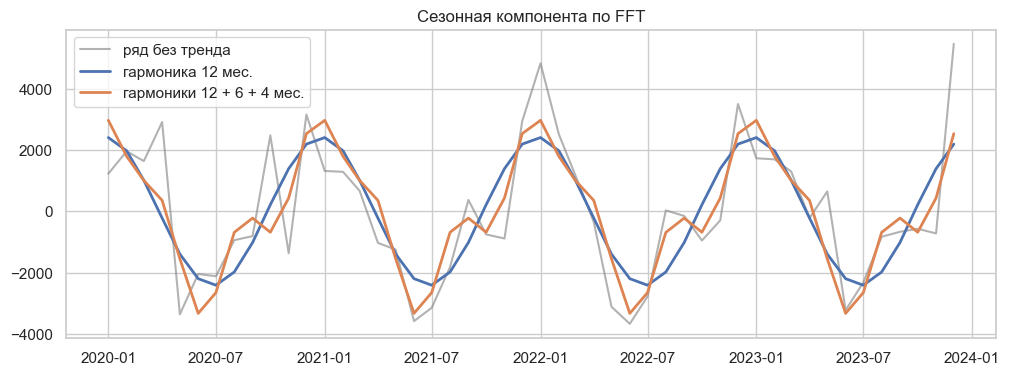

Доля дисперсии (без тренда), объяснённая гармоникой 12 мес.: 61.2%
Гармоники 12+6+4 мес.: 72.0%


In [12]:
# Проверка значимости пика: простой тест Фишера для периодограммы (g = max(I)/sum(I)).
# H0: белый шум; малый p-value => в ряде есть значимая периодическая компонента.
I = np.abs(np.fft.rfft(detr))[1:n // 2] ** 2
g = I.max() / I.sum()
m = len(I)
# точное p-value Фишера: P(g > x) = sum_{k=1}^{floor(1/x)} (-1)^(k-1) C(m,k) (1-k x)^(m-1)
from math import comb
pF = sum((-1) ** (k - 1) * comb(m, k) * (1 - k * g) ** (m - 1) for k in range(1, int(1 / g) + 1))
print(f'Доминирующий период: {n / (np.argmax(I) + 1):.2f} мес. | статистика Фишера g = {g:.3f} | p-value ≈ {min(max(pF, 0), 1):.2e}')

# Реконструкция сезонной компоненты по первым гармоникам (k = 4 -> период 12, 8 -> 6, 12 -> 4 мес.)
F = np.fft.rfft(detr)
def recon(harmonics):
    Fk = np.zeros_like(F); Fk[harmonics] = F[harmonics]
    return np.fft.irfft(Fk, n=n)
fft_seas = recon([4]); fft_seas3 = recon([4, 8, 12])
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y.index, detr, c='gray', alpha=.6, label='ряд без тренда')
ax.plot(y.index, fft_seas, lw=2, label='гармоника 12 мес.')
ax.plot(y.index, fft_seas3, lw=2, label='гармоники 12 + 6 + 4 мес.')
ax.legend(); ax.set_title('Сезонная компонента по FFT'); plt.show()
print('Доля дисперсии (без тренда), объяснённая гармоникой 12 мес.: %.1f%%' % (100 * np.var(fft_seas) / np.var(detr)))
print('Гармоники 12+6+4 мес.: %.1f%%' % (100 * np.var(fft_seas3) / np.var(detr)))

### 2.1.4. Метод 3 — вейвлет-анализ (непрерывный вейвлет Морле + дискретный Добеши)

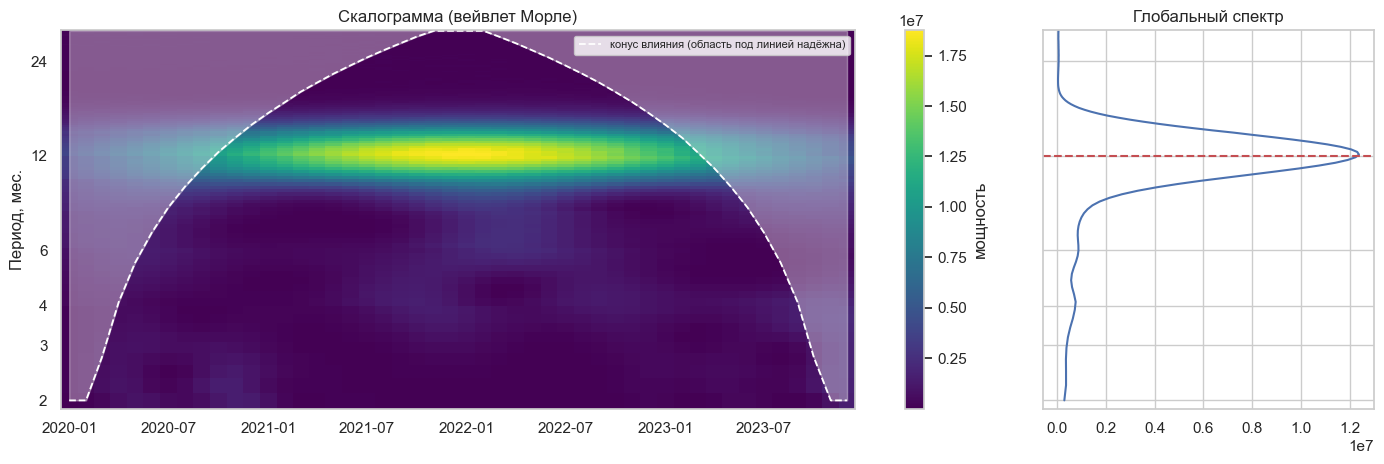

Период максимума глобального вейвлет-спектра: 12.1 мес.


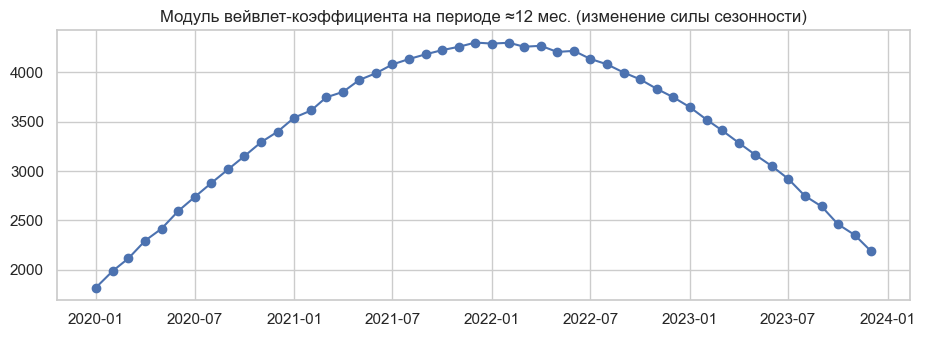

In [13]:
# Непрерывное вейвлет-преобразование (CWT) с комплексным вейвлетом Морле.
# Задаём сетку периодов 2..30 мес. и переводим в масштабы: scale = fc / (f * dt)
wavelet = 'cmor1.5-1.0'
periods = np.linspace(2, 30, 120)
freqs = 1 / periods
scales = pywt.central_frequency(wavelet) / freqs
x = (y.values - y.values.mean())                         # центрируем ряд
coef, fr = pywt.cwt(x, scales, wavelet, sampling_period=1.0)
power = np.abs(coef) ** 2

# Конус влияния (COI): за его пределами (у краёв) оценки искажены краевыми эффектами.
# e-folding time для Морле ~ 0.73*период (прибл.); отмечаем области, где 0.73*период > расстояние до края.
dist_edge = np.minimum(np.arange(n), n - 1 - np.arange(n))
coi_period = dist_edge / 0.73

fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [3, 1]}, sharey=True)
im = axs[0].pcolormesh(y.index, periods, power, shading='auto', cmap='viridis')
axs[0].plot(y.index, np.clip(coi_period, 2, 30), 'w--', lw=1.3, label='конус влияния (область под линией надёжна)')
axs[0].fill_between(y.index, np.clip(coi_period, 2, 30), 30, color='white', alpha=.35)
axs[0].set_yscale('log', base=2); axs[0].set_yticks([2, 3, 4, 6, 12, 24]); axs[0].set_yticklabels([2, 3, 4, 6, 12, 24])
axs[0].set_ylabel('Период, мес.'); axs[0].set_title('Скалограмма (вейвлет Морле)'); axs[0].legend(loc='upper right', fontsize=8)
plt.colorbar(im, ax=axs[0], label='мощность')
gws = power.mean(axis=1)                                  # глобальный вейвлет-спектр
axs[1].plot(gws, periods); axs[1].set_title('Глобальный спектр'); axs[1].axhline(12, ls='--', c='r')
plt.tight_layout(); plt.show()
print(f'Период максимума глобального вейвлет-спектра: {periods[np.argmax(gws)]:.1f} мес.')

# Амплитуда сезонной (≈12 мес.) компоненты во времени — меняется ли сезонность?
i12 = np.argmin(np.abs(periods - 12))
amp12 = np.abs(coef[i12])
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(y.index, amp12, marker='o'); ax.set_title('Модуль вейвлет-коэффициента на периоде ≈12 мес. (изменение силы сезонности)')
plt.show()

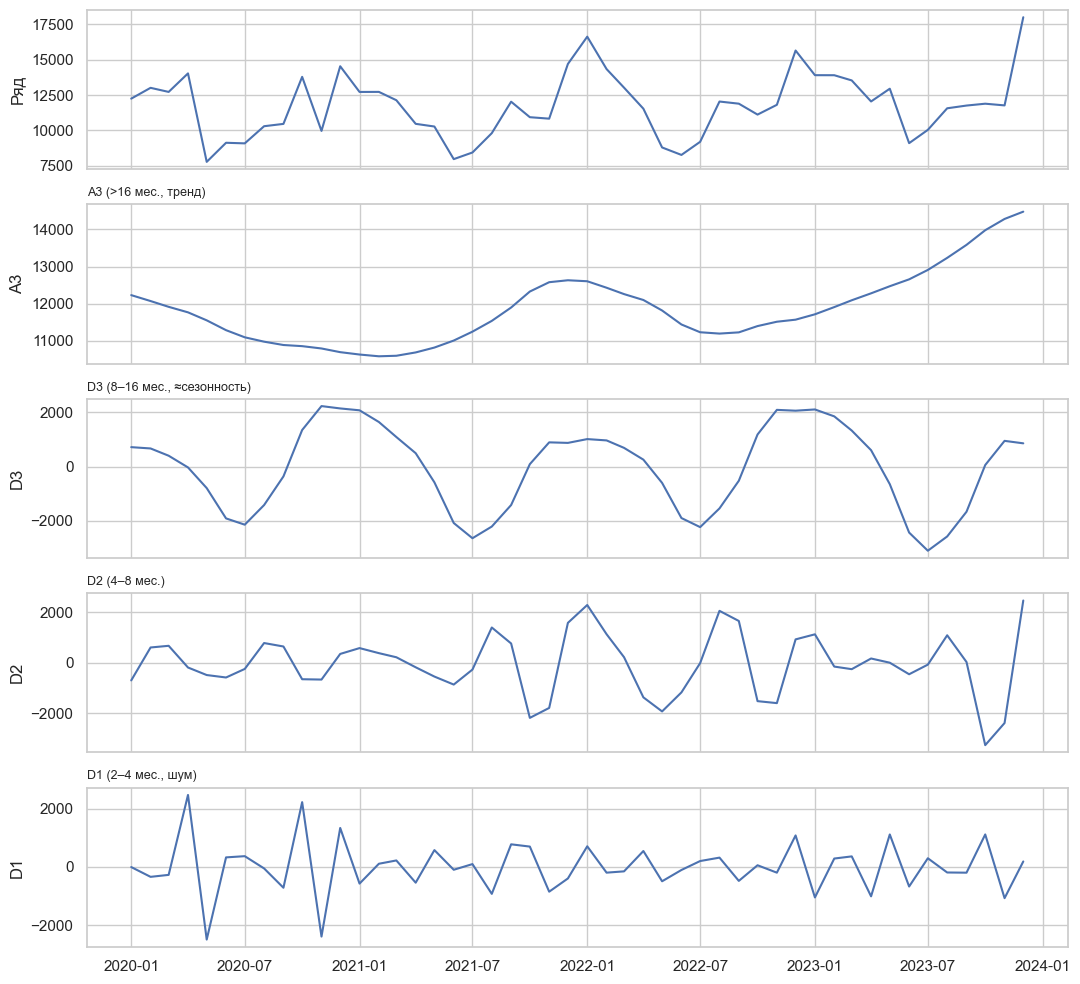

,A3,D3,D2,D1
"Доля энергии, %",16.400,42.500,26.500,14.700


Проверка восстановления ряда: max|y - sum(parts)| = 0.0


In [14]:
# Дискретное вейвлет-разложение Добеши (db4): ряд = A_J + D_J + ... + D_1.
# При n = 48 доступно максимум ~3 уровня; используем уровень 3 (swt даёт сдвиг-инвариантное разложение той же длины).
w = 'db4'
level = 3
coeffs = pywt.wavedec(y.values, w, level=level, mode='symmetric')
names = [f'A{level}'] + [f'D{l}' for l in range(level, 0, -1)]

# Реконструкция каждой компоненты по отдельности (остальные коэффициенты обнуляем)
parts = {}
for i, name in enumerate(names):
    c = [np.zeros_like(cc) for cc in coeffs]; c[i] = coeffs[i]
    parts[name] = pywt.waverec(c, w, mode='symmetric')[:n]
parts = pd.DataFrame(parts, index=y.index)

# Соответствие уровней периодам (для dt = 1 мес.): D1: 2–4, D2: 4–8, D3: 8–16, A3: >16 мес.
fig, axs = plt.subplots(len(names) + 1, 1, figsize=(11, 10), sharex=True)
axs[0].plot(y); axs[0].set_ylabel('Ряд')
labels = {'A3': 'A3 (>16 мес., тренд)', 'D3': 'D3 (8–16 мес., ≈сезонность)', 'D2': 'D2 (4–8 мес.)', 'D1': 'D1 (2–4 мес., шум)'}
for ax, nm in zip(axs[1:], names): ax.plot(parts[nm]); ax.set_ylabel(nm); ax.set_title(labels[nm], fontsize=9, loc='left')
plt.tight_layout(); plt.show()

energy = (parts - parts.mean()).pow(2).sum()
display((100 * energy / energy.sum()).round(1).to_frame('Доля энергии, %').T)
print('Проверка восстановления ряда: max|y - sum(parts)| =', np.abs(y.values - parts.sum(axis=1).values).max().round(8))

### 2.1.5. Сравнение методов декомпозиции

In [15]:
# Сводная таблица: что каждый метод сообщил о ряде
summary = pd.DataFrame({
    'Классическая (add/mult)': ['Тренд (скольз. среднее) + постоянный сезонный профиль', f'12 мес. (задаётся)', 'Теряет по 6 точек с каждого края тренда/остатка', 'Простота, наглядный профиль по месяцам'],
    'STL': ['Тренд + сезонность, которая может медленно меняться', '12 мес. (задаётся)', 'Нет потери краёв; устойчивость (robust) к выбросам', 'Гибкость, но параметры сглаживания влияют на результат'],
    'FFT': ['Спектр амплитуд (стационарная периодичность)', f'{n / (np.argmax(I) + 1):.1f} мес. (найден)', 'Нет информации о времени; утечка при коротком ряде (48 точек)', 'Объективно находит периоды без предположений'],
    'Вейвлет (Морле/db4)': ['Время-частотное разложение', f'{periods[np.argmax(gws)]:.1f} мес. (найден)', 'Краевые эффекты (конус влияния), мало данных для низких частот', 'Показывает, как период и амплитуда меняются во времени'],
}, index=['Что даёт', 'Найденный период сезонности', 'Ограничения на нашем ряде', 'Преимущество']).T
display(summary)

,Что даёт,Найденный период сезонности,Ограничения на нашем ряде,Преимущество
Классическая (add/mult),Тренд (скольз. среднее) + постоянный сезонный ...,12 мес. (задаётся),Теряет по 6 точек с каждого края тренда/остатка,"Простота, наглядный профиль по месяцам"
STL,"Тренд + сезонность, которая может медленно мен...",12 мес. (задаётся),Нет потери краёв; устойчивость (robust) к выбр...,"Гибкость, но параметры сглаживания влияют на р..."
FFT,Спектр амплитуд (стационарная периодичность),12.0 мес. (найден),Нет информации о времени; утечка при коротком ...,Объективно находит периоды без предположений
Вейвлет (Морле/db4),Время-частотное разложение,12.1 мес. (найден),"Краевые эффекты (конус влияния), мало данных д...","Показывает, как период и амплитуда меняются во..."


## Аналитические выводы по этапу 2.1

**Свойства ряда.** 48 месячных наблюдений без пропусков; среднее ≈ 11 769, СКО ≈ 2 258, минимум 7 783 (май 2020), максимум 17 996 (декабрь 2023). Линейный тренд практически отсутствует (+32 ед./мес., p ≈ 0.18, R² ≈ 0.04); среднегодовой уровень колеблется (11 422 → 11 088 → 12 025 → 12 539). ADF отвергает единичный корень (p ≈ 0.0002), KPSS не отвергает стационарность (p ≥ 0.1): ряд стационарен относительно константы, главная структура — **сезонность**, а не тренд.

**Сезонность и внешние факторы.** Профиль устойчив из года в год: пик в декабре (в среднем 15 718 против 11 190 в «обычные» месяцы), высокий уровень в январе–марте, провал в мае–июле (минимум в июне, ≈ 8 621). Месяцы с акциями в среднем выше обычных (≈ 12 800 против ≈ 11 190), но таких наблюдений всего 6 и разброс велик. `HolidayMonth` совпадает только с декабрём, т.е. по смыслу дублирует сезонный эффект.

**Декомпозиция.** Все три варианта дают близкий результат: сила сезонности Fs ≈ 0.83–0.84, СКО остатка ≈ 871 (аддитивная), 877 (мультипликативная), 883 (STL). Остатки не автокоррелированы (Ljung–Box p = 0.61 / 0.68 / 0.13), но по Шапиро–Уилку слегка отклоняются от нормальности (p ≈ 0.03 / 0.03 / <0.001) — вероятно, из-за выбросов в месяцы с акциями. Отношение размаха внутри года к среднему уровню растёт лишь умеренно (0.59 → 0.71), а остатки аддитивной и мультипликативной моделей практически не различаются, поэтому **аддитивная модель предпочтительнее как более простая**. STL удобнее классической декомпозиции: не теряет по 6 точек на краях и устойчива к выбросам.

**FFT.** Доминирует период **12.0 мес.** (≈ 60 % спектральной энергии, амплитуда ≈ 2 421; тест Фишера p ≈ 9·10⁻⁹). Остальные гармоники (4, 6, 2.4 мес.) дают по 2–7 % и по отдельности малозначимы; гармоника 12 мес. объясняет ≈ 61 % дисперсии ряда без тренда, вместе с 6 и 4 мес. — ≈ 72 %.

**Вейвлеты.** Скалограмма Морле показывает устойчивую полосу вокруг периода ≈ 12 мес. на всём протяжении ряда, глобальный вейвлет-спектр имеет максимум на 12.1 мес. Дискретное разложение db4: наибольшая доля энергии у уровня D3 (периоды 8–16 мес., ≈ 42 %), т.е. это сезонная компонента; D2 — 27 %, D1 (шум) — 15 %, A3 (медленная составляющая) — 16 %. На краях ряда оценки ненадёжны (конус влияния), а при n = 48 доступно всего три уровня DWT.

**Сравнение методов и применимость.**

| Метод | Преимущества | Ограничения на нашем ряде |
|---|---|---|
| Классическая (add/mult) | простота, наглядный сезонный профиль, легко интерпретировать | постоянная сезонность; тренд/остаток не определены на 6 точках с каждого края; чувствительна к выбросам |
| STL | нет потери краёв, робастность, допускает медленно меняющуюся сезонность | нужно задавать период и параметры сглаживания; аддитивная форма |
| FFT | объективно находит периоды, не требует их заранее; есть статистический тест | теряет время (предполагает постоянство периодичности); при n = 48 низкое частотное разрешение (1/48) и утечка спектра |
| Вейвлеты | показывают, как период и амплитуда меняются во времени; не требуют стационарности | краевые эффекты (конус влияния занимает значительную часть короткого ряда); результат зависит от выбора вейвлета |

Все три подхода независимо подтверждают единственную значимую периодичность — **12 месяцев**. Для прогноза это означает: нужны модели с сезонной компонентой (s = 12), а регрессор «праздничный месяц» при сезонном разностировании избыточен.

# 2.2. Построение прогнозных моделей

### 2.2.1. Разбиение на обучающую и тестовую выборки и обоснование порядков

Ряд короткий (48 точек), а сезонный период равен 12. Тестовую выборку берём равной **одному сезонному циклу (12 мес.)**: этого достаточно, чтобы увидеть и сезонный пик декабря, и оценить деградацию прогноза с ростом горизонта. На обучение остаётся 36 точек (3 цикла).

Выбор параметров опирается на результаты EDA:
- **d = 0 (с константой)** — по ADF/KPSS (см. 2.1.1) исходный ряд стационарен, линейный тренд статистически незначим (p ≈ 0.18), единичного корня нет.
- **s = 12, D = 1** — сезонность подтверждена всеми тремя методами (декомпозиция, FFT, вейвлеты). Для полного ряда Δ12 стационарен (ADF p ≈ 0.005); на обучающей выборке из 24 точек после Δ12 ADF малочувствителен (мощность теста низкая), поэтому решение о D=1 принимаем по результатам спектрального и вейвлет-анализа, а не только по ADF.
- **p, q, P, Q** — по ACF/PACF и сеточному поиску с критерием **AIC на обучающей выборке** (тестовые данные в выборе не участвуют, чтобы не было утечки).
- **Экзогенные регрессоры для SARIMAX:** `Promotion` (план акций известен заранее). Признак `HolidayMonth` **не включаем**: в данных он равен 1 только в декабре, а сезонное разностирование Δ12 уже полностью убирает постоянный декабрьский эффект — после Δ12 этот регрессор в обучающей выборке тождественно равен нулю (проверяется в ячейке ниже), и его коэффициент не идентифицируем.

Δ12 HolidayMonth (train): ненулевых значений = 0
Δ12 Promotion    (train): ненулевых значений = 6


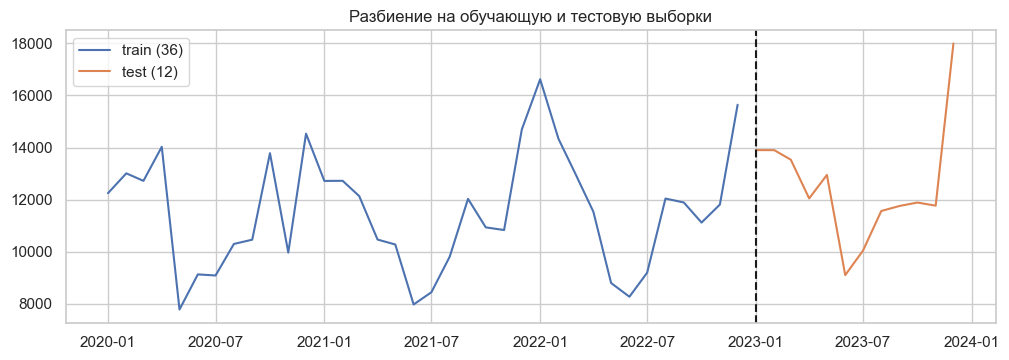

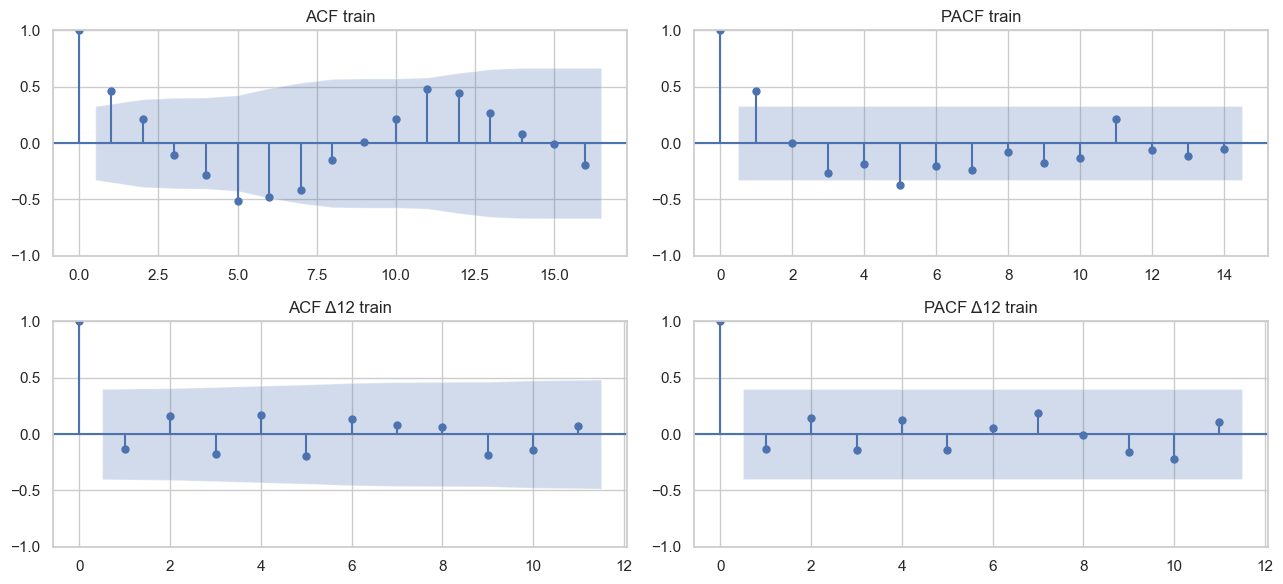

ADF (train, исходный) p = 0.0032 | ADF (train, Δ12) p = 0.5078


In [16]:
TEST = 12
y_tr, y_te = y.iloc[:-TEST], y.iloc[-TEST:]
XS = X[['Promotion']]                                   # экзогенные регрессоры SARIMAX (см. пояснение выше)
X_tr, X_te = XS.iloc[:-TEST], XS.iloc[-TEST:]

# Проверка: после сезонной разности Δ12 признак HolidayMonth в train тождественно равен 0, Promotion — нет
print('Δ12 HolidayMonth (train): ненулевых значений =', int((X['HolidayMonth'].iloc[:-TEST].diff(12).dropna() != 0).sum()))
print('Δ12 Promotion    (train): ненулевых значений =', int((X['Promotion'].iloc[:-TEST].diff(12).dropna() != 0).sum()))

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(y_tr, label=f'train ({len(y_tr)})'); ax.plot(y_te, c='C1', label=f'test ({len(y_te)})')
ax.axvline(y_te.index[0], ls='--', c='k'); ax.legend(); ax.set_title('Разбиение на обучающую и тестовую выборки'); plt.show()

# ACF/PACF обучающей выборки и её сезонной разности — ориентиры для порядков
fig, axs = plt.subplots(2, 2, figsize=(13, 6))
plot_acf(y_tr, lags=16, ax=axs[0, 0]); axs[0, 0].set_title('ACF train')
plot_pacf(y_tr, lags=14, ax=axs[0, 1], method='ywm'); axs[0, 1].set_title('PACF train')
plot_acf(y_tr.diff(12).dropna(), lags=11, ax=axs[1, 0]); axs[1, 0].set_title('ACF Δ12 train')
plot_pacf(y_tr.diff(12).dropna(), lags=11, ax=axs[1, 1], method='ywm'); axs[1, 1].set_title('PACF Δ12 train')
plt.tight_layout(); plt.show()
print('ADF (train, исходный) p =', round(adfuller(y_tr)[1], 4), '| ADF (train, Δ12) p =', round(adfuller(y_tr.diff(12).dropna())[1], 4))

### 2.2.2. ARIMA — подбор порядка (d = 0, константа)

In [29]:
# Перебор p, q ∈ {0..3} при d = 0 с константой. Критерий отбора — AIC на обучающей выборке.
rows = []
for p, q in itertools.product(range(4), range(4)):
    try:
        r = SARIMAX(y_tr, order=(p, 0, q), trend='c').fit(disp=False, maxiter=300)
        rows.append({'p': p, 'd': 0, 'q': q, 'AIC': r.aic, 'BIC': r.bic})
    except Exception as e:
        pass
arima_grid = pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)
display(arima_grid.head(6))
ARIMA_ORDER = tuple(int(v) for v in arima_grid.loc[0, ['p', 'd', 'q']])
print('Выбран порядок ARIMA:', ARIMA_ORDER)

,p,d,q,AIC,BIC
0,1,0,0,653.040,657.791
1,0,0,2,654.022,660.356
2,3,0,0,654.110,662.027
3,3,0,1,654.957,664.458
4,2,0,0,655.042,661.376
5,1,0,1,655.105,661.439


Выбран порядок ARIMA: (1, 0, 0)


### 2.2.3. SARIMAX — подбор порядка (D = 1, s = 12, экзогенная Promotion)

In [18]:
# Перебор p, q ∈ {0..2}, P, Q ∈ {0..1} при d = 0, D = 1, s = 12, экзогенной Promotion и константе (trend='c': при D=1 она
# задаёт средний годовой прирост относительно того же месяца прошлого года) / без неё. Критерий — AIC.
# Сетка небольшая намеренно: после Δ12 в обучающей выборке остаётся всего 24 точки.
# Фильтр «регулярности»: отбрасываем модели, не сошедшиеся или с корнями AR/MA на границе единичной окружности
# (|корень| < 1.05). Такие модели имеют вырожденную поверхность правдоподобия (нулевые стандартные ошибки,
# сокращение AR- и MA-множителей) и формально занижают AIC, но им нельзя доверять.
rows = []
for trd, p, q, P, Q in itertools.product([None, 'c'], range(3), range(3), range(2), range(2)):
    try:
        r = SARIMAX(y_tr, exog=X_tr, order=(p, 0, q), seasonal_order=(P, 1, Q, 12), trend=trd).fit(disp=False, maxiter=300)
        roots = np.concatenate([np.abs(r.arroots), np.abs(r.maroots)]) if (len(r.arroots) + len(r.maroots)) else np.array([np.inf])
        rows.append({'trend': trd or 'нет', 'p': p, 'd': 0, 'q': q, 'P': P, 'D': 1, 'Q': Q, 'AIC': r.aic, 'BIC': r.bic,
                     'conv': r.mle_retvals.get('converged', True), 'min |root|': roots.min()})
    except Exception as e:
        pass
sarimax_all = pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)
print('Лучшие по AIC БЕЗ фильтра (обратите внимание на min |root| ≈ 1 — вырожденные модели):')
display(sarimax_all.head(4))
sarimax_grid = sarimax_all[sarimax_all.conv & (sarimax_all['min |root|'] > 1.05)].reset_index(drop=True)
print('Лучшие по AIC ПОСЛЕ фильтра регулярности:')
display(sarimax_grid.head(8))
SARIMAX_ORDER = tuple(int(v) for v in sarimax_grid.loc[0, ['p', 'd', 'q']])
SARIMAX_SEAS = tuple(int(v) for v in sarimax_grid.loc[0, ['P', 'D', 'Q']]) + (12,)
SARIMAX_TREND = None if sarimax_grid.loc[0, 'trend'] == 'нет' else 'c'
print('Выбран порядок SARIMAX:', SARIMAX_ORDER, SARIMAX_SEAS, '| trend =', SARIMAX_TREND)

Лучшие по AIC БЕЗ фильтра (обратите внимание на min |root| ≈ 1 — вырожденные модели):


,trend,p,d,q,P,D,Q,AIC,BIC,conv,min |root|
0,c,0,0,1,0,1,1,388.791,394.682,True,1.091
1,c,0,0,0,1,1,1,388.827,394.718,True,1.000
2,c,1,0,0,0,1,1,388.858,394.748,True,1.092
3,c,0,0,1,1,1,0,389.134,395.024,True,1.122


Лучшие по AIC ПОСЛЕ фильтра регулярности:


,trend,p,d,q,P,D,Q,AIC,BIC,conv,min |root|
0,c,0,0,1,0,1,1,388.791,394.682,True,1.091
1,c,1,0,0,0,1,1,388.858,394.748,True,1.092
2,c,0,0,1,1,1,0,389.134,395.024,True,1.122
3,c,2,0,0,0,1,1,390.786,397.854,True,1.093
4,c,0,0,2,0,1,1,390.891,397.959,True,1.104
5,c,1,0,1,0,1,1,390.928,397.996,True,1.091
6,c,2,0,0,1,1,0,391.014,398.082,True,1.122
7,c,0,0,2,1,1,0,391.103,398.171,True,1.130


Выбран порядок SARIMAX: (0, 0, 1) (0, 1, 1, 12) | trend = c


In [19]:
# Финальное обучение обеих моделей на train
m_arima = SARIMAX(y_tr, order=ARIMA_ORDER, trend='c').fit(disp=False, maxiter=500)
m_sarimax = SARIMAX(y_tr, exog=X_tr, order=SARIMAX_ORDER, seasonal_order=SARIMAX_SEAS, trend=SARIMAX_TREND).fit(disp=False, maxiter=500)
print(m_arima.summary().tables[1]); print()
print(m_sarimax.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   5689.0445   2111.812      2.694      0.007    1549.970    9828.119
ar.L1          0.5110      0.176      2.910      0.004       0.167       0.855
sigma2      3.808e+06      2.141   1.78e+06      0.000    3.81e+06    3.81e+06

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept   1000.4160    213.978      4.675      0.000     581.026    1419.806
Promotion   2624.5663    315.877      8.309      0.000    2005.458    3243.674
ma.L1          0.0226      0.142      0.159      0.873      -0.256       0.301
ma.S.L12      -0.3519      0.173     -2.030      0.042      -0.692      -0.012
sigma2      3.871e+05   1.79e+05      2.158      0.031    3.55e+04    7.39e+05


### 2.2.4. Прогноз и выбор горизонта

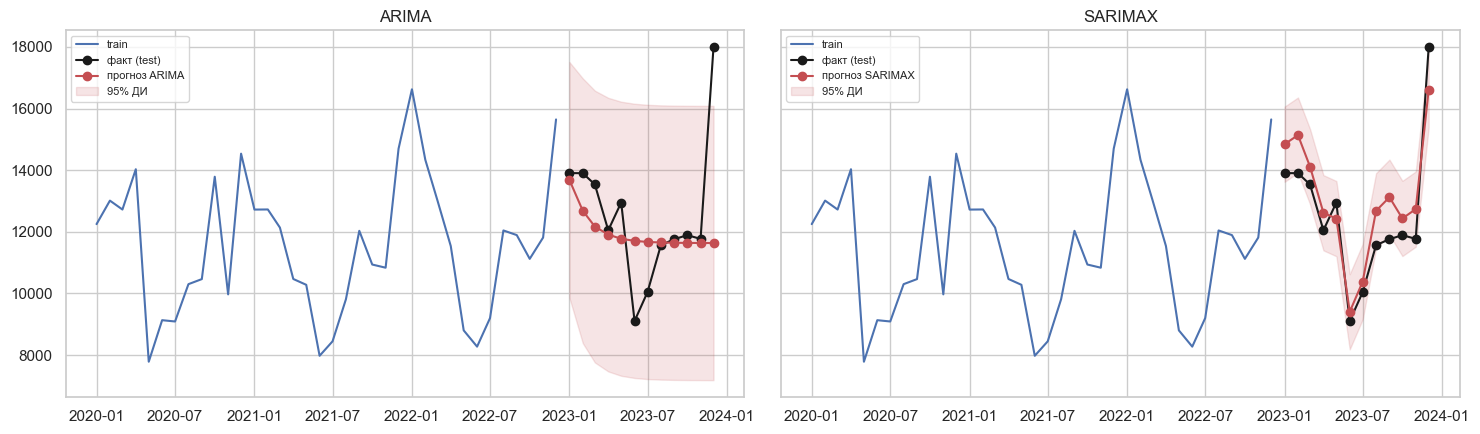

,fact,ARIMA,SARIMAX,Seasonal naive
2023-01-01,"13,904.000","13,683.000","14,841.000","16,623.000"
2023-02-01,"13,901.000","12,681.000","15,136.000","14,336.000"
2023-03-01,"13,534.000","12,169.000","14,112.000","13,023.000"
2023-04-01,"12,048.000","11,907.000","12,617.000","11,537.000"
2023-05-01,"12,949.000","11,773.000","12,426.000","8,800.000"
2023-06-01,"9,104.000","11,705.000","9,405.000","8,273.000"
2023-07-01,"10,042.000","11,670.000","10,381.000","9,199.000"
2023-08-01,"11,566.000","11,652.000","12,679.000","12,043.000"
2023-09-01,"11,759.000","11,643.000","13,121.000","11,892.000"
2023-10-01,"11,890.000","11,639.000","12,432.000","11,121.000"


In [20]:
# Прогноз на 12 месяцев вперёд (весь тестовый период) с доверительными интервалами 95%.
fc_arima = m_arima.get_forecast(TEST)
fc_sarimax = m_sarimax.get_forecast(TEST, exog=X_te)
pred = pd.DataFrame({'fact': y_te,
                     'ARIMA': fc_arima.predicted_mean, 'SARIMAX': fc_sarimax.predicted_mean})
# Сезонный наивный прогноз (значение того же месяца год назад) — бенчмарк для оценки полезности моделей
pred['Seasonal naive'] = y.shift(12).iloc[-TEST:]

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (nm, fc) in zip(axs, [('ARIMA', fc_arima), ('SARIMAX', fc_sarimax)]):
    ci = fc.conf_int(alpha=.05)
    ax.plot(y_tr, c='C0', label='train'); ax.plot(y_te, c='k', marker='o', label='факт (test)')
    ax.plot(fc.predicted_mean, c='C3', marker='o', label=f'прогноз {nm}')
    ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color='C3', alpha=.15, label='95% ДИ')
    ax.set_title(f'{nm}'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pred.round(0))

,MAPE ARIMA,Skill ARIMA,MAPE SARIMAX,Skill SARIMAX,MAPE Seasonal naive,Skill Seasonal naive
h,,,,,,
1,1.590,0.990,6.740,0.850,19.560,-0.290
2,5.180,0.870,7.810,0.790,11.340,0.340
3,6.820,0.780,6.630,0.820,8.820,0.490
4,5.400,0.780,6.160,0.810,7.680,0.490
5,6.140,0.730,5.730,0.810,12.550,-0.420
6,9.880,0.510,5.330,0.860,11.980,-0.100
7,10.780,0.450,5.050,0.860,11.470,-0.030
8,9.530,0.450,5.620,0.810,10.550,-0.040
9,8.580,0.450,6.280,0.740,9.500,-0.040


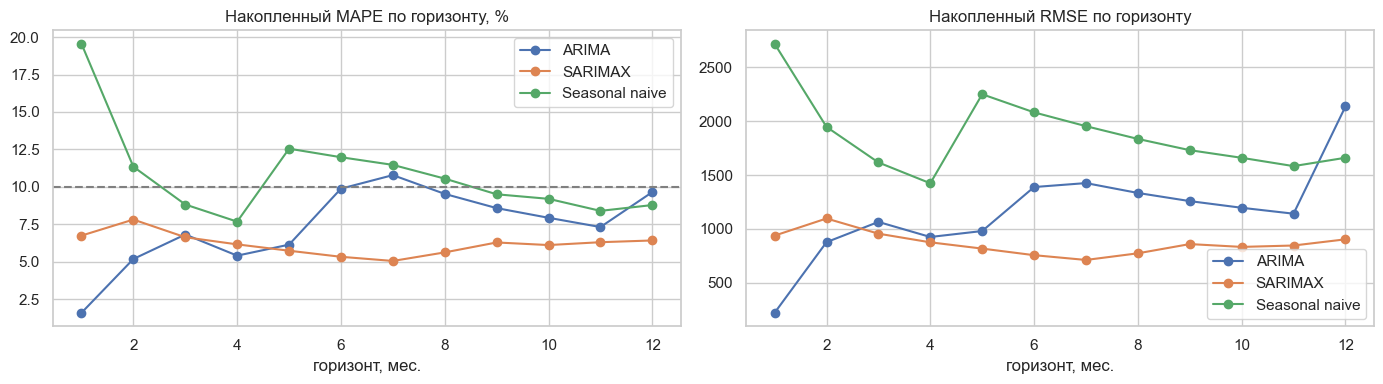

Максимальный горизонт с приемлемым качеством (непрерывно с h=1): {'ARIMA': 6, 'SARIMAX': 12, 'Seasonal naive': 0}


In [21]:
# Качество прогноза в зависимости от горизонта h: считаем метрики на первых h точках теста.
# Критерий «приемлемого качества» (задан заранее): на горизонте h модель
#   (1) лучше константного прогноза (среднее train): R² относительно ряда test > 0, и
#   (2) MAPE ≤ 10 %.
# Из-за малой длины теста R² на малых h шумный, поэтому дополнительно смотрим MAPE и скользящий RMSE.
def mape(a, f): return np.mean(np.abs((a - f) / a)) * 100

mean_fc = y_tr.mean()
rows = []
for h in range(1, TEST + 1):
    a = y_te.iloc[:h]
    row = {'h': h}
    for nm in ['ARIMA', 'SARIMAX', 'Seasonal naive']:
        f = pred[nm].iloc[:h]
        row[f'MSE {nm}'] = mean_squared_error(a, f)
        row[f'MAPE {nm}'] = mape(a, f)
        row[f'Skill {nm}'] = 1 - mean_squared_error(a, f) / mean_squared_error(a, np.full(h, mean_fc))   # >0 — лучше среднего
    rows.append(row)
hor = pd.DataFrame(rows).set_index('h')
display(hor[[c for c in hor.columns if c.startswith('MAPE') or c.startswith('Skill')]].round(2))

fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for nm in ['ARIMA', 'SARIMAX', 'Seasonal naive']:
    axs[0].plot(hor.index, hor[f'MAPE {nm}'], marker='o', label=nm)
    axs[1].plot(hor.index, np.sqrt(hor[f'MSE {nm}']), marker='o', label=nm)
axs[0].axhline(10, ls='--', c='gray'); axs[0].set_title('Накопленный MAPE по горизонту, %'); axs[0].set_xlabel('горизонт, мес.'); axs[0].legend()
axs[1].set_title('Накопленный RMSE по горизонту'); axs[1].set_xlabel('горизонт, мес.'); axs[1].legend()
plt.tight_layout(); plt.show()

def max_horizon(nm):
    ok = (hor[f'MAPE {nm}'] <= 10) & (hor[f'Skill {nm}'] > 0)
    # максимальный h, при котором критерий выполняется НЕПРЕРЫВНО с h = 1
    h_ok = 0
    for h in hor.index:
        if ok.loc[h]: h_ok = h
        else: break
    return h_ok
HORIZON = {nm: max_horizon(nm) for nm in ['ARIMA', 'SARIMAX', 'Seasonal naive']}
print('Максимальный горизонт с приемлемым качеством (непрерывно с h=1):', HORIZON)

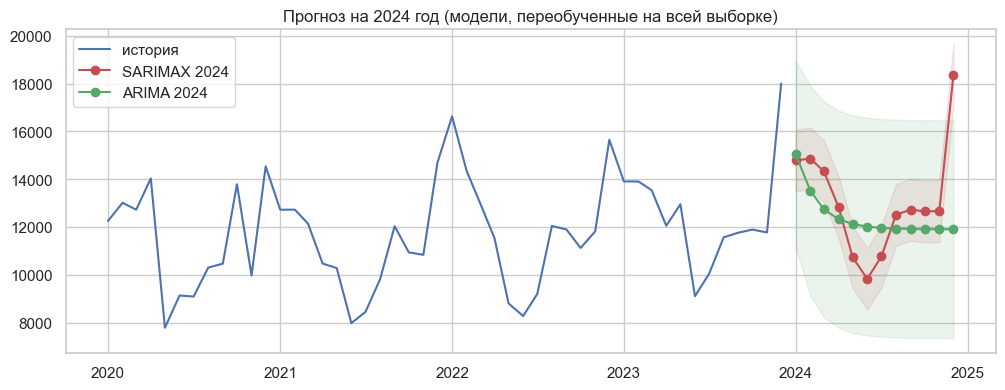

In [22]:
# Прогноз «в будущее» на 2024 год: переобучаем выбранные модели на всех 48 точках.
# Предположение о будущей экзогенной переменной: акций в 2024 году нет (Promotion = 0). Декабрьский пик заложен сезонной компонентой.
future_idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(), periods=12, freq='MS')
X_fut = pd.DataFrame({'Promotion': 0.0}, index=future_idx)

full_sarimax = SARIMAX(y, exog=XS, order=SARIMAX_ORDER, seasonal_order=SARIMAX_SEAS, trend=SARIMAX_TREND).fit(disp=False, maxiter=500)
full_arima = SARIMAX(y, order=ARIMA_ORDER, trend='c').fit(disp=False, maxiter=500)
f_s = full_sarimax.get_forecast(12, exog=X_fut); f_a = full_arima.get_forecast(12)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(y, label='история')
for nm, f, c in [('SARIMAX', f_s, 'C3'), ('ARIMA', f_a, 'C2')]:
    ci = f.conf_int(); ax.plot(f.predicted_mean, c=c, marker='o', label=f'{nm} 2024'); ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color=c, alpha=.12)
ax.legend(); ax.set_title('Прогноз на 2024 год (модели, переобученные на всей выборке)'); plt.show()

## Аналитические выводы по этапу 2.2

- **Разбиение:** train = 36 точек (2020–2022), test = 12 точек (2023, один сезонный цикл). Это максимальный горизонт, на котором можно проверить прогноз по фактическим данным.
- **ARIMA(1,0,0) с константой.** По ADF/KPSS ряд стационарен, поэтому d = 0; порядок выбран по AIC на train (AIC = 653.0). Оценки: AR(1) ≈ 0.51 (p = 0.004), константа ≈ 5 689, что соответствует среднему ≈ 11 600. Модель не содержит сезонности, поэтому быстро «сходится» к среднему: после 3–4 месяцев прогноз практически плоский (≈ 11 600–11 700), модель **не видит ни июньского провала, ни декабрьского пика**.
- **SARIMAX(0,0,1)(0,1,1)₁₂ + константа + `Promotion`.** Сезонное разностирование (D = 1, s = 12) следует из EDA. Константа при D = 1 задаёт средний годовой прирост относительно того же месяца прошлого года; её добавление улучшило AIC примерно на 13 единиц (≈ 402 → ≈ 389), оценка ≈ 1 000 значима (p < 0.001). Эффект акции **+2 625** единиц продаж (p < 0.001). `HolidayMonth` исключён намеренно: после Δ12 в обучающей выборке он тождественно равен нулю, декабрьский пик заложен самой сезонной разностью.
- **Фильтр регулярности.** Без него по AIC «побеждали» модели с корнем AR на границе единичной окружности (|корень| = 1.00) и нулевыми стандартными ошибками — признак вырожденной поверхности правдоподобия. Мы исключили такие модели; из оставшихся лучшая — указанная выше (альтернативы (1,0,0)(0,1,1) и (0,0,1)(1,1,0) отличаются по AIC менее чем на 0.4, т.е. статистически неотличимы). Несезонная MA(1)-компонента статистически незначима (p ≈ 0.87), а сезонная MA значима на уровне 5 % (≈ −0.35, p ≈ 0.04); основную работу делают сезонная разность, акция и константа.
- **Горизонт прогноза.** Критерий «приемлемого качества» (задан до расчётов): накопленный MAPE ≤ 10 % и модель лучше константного прогноза. ARIMA удовлетворяет ему до **6 мес.** (на 7-м месяце MAPE ≈ 10.8 %), SARIMAX — на **всех 12 мес.** (MAPE 5–8 %), сезонный наивный прогноз критерий не проходит. На горизонт больше 12 мес. качество проверить нельзя — тестовая выборка короче; прогноз на 2024 год построен, но его надёжность дальше первых 12 мес. не подтверждена, а доверительные интервалы расширяются.
- **Ограничения:** очень короткая обучающая выборка (после Δ12 остаётся 24 точки), поэтому сетка параметров намеренно мала, а выбор порядков неустойчив; прогноз 2024 г. опирается на предположение об отсутствии акций.

# 2.3. Оценка качества моделей

### 2.3.1. Метрики прогноза (MSE, R²) и информационные критерии (AIC, BIC)

In [23]:
def metrics(a, f):
    return {'MSE': mean_squared_error(a, f), 'RMSE': np.sqrt(mean_squared_error(a, f)),
            'MAE': mean_absolute_error(a, f), 'MAPE, %': mape(a, f), 'R²': r2_score(a, f)}

# Метрики на ТЕСТЕ (полный горизонт 12 мес.)
tab = pd.DataFrame({nm: metrics(y_te, pred[nm]) for nm in ['ARIMA', 'SARIMAX', 'Seasonal naive']}).T

# Метрики на TRAIN (in-sample одношаговые предсказания). Для SARIMAX первые 12 значений — burn-in сезонной разности: исключаем.
fit_arima = m_arima.fittedvalues
fit_sarimax = m_sarimax.fittedvalues
burn = 12
tab_tr = pd.DataFrame({'ARIMA': metrics(y_tr.iloc[burn:], fit_arima.iloc[burn:]),
                       'SARIMAX': metrics(y_tr.iloc[burn:], fit_sarimax.iloc[burn:])}).T

ic = pd.DataFrame({'AIC': [m_arima.aic, m_sarimax.aic], 'BIC': [m_arima.bic, m_sarimax.bic],
                   'Число параметров': [len(m_arima.params), len(m_sarimax.params)],
                   'Наблюдений в likelihood': [int(m_arima.nobs_effective), int(m_sarimax.nobs_effective)]}, index=['ARIMA', 'SARIMAX'])
print('--- TEST (12 мес.) ---'); display(tab)
print('--- TRAIN (in-sample, без первых 12 точек) ---'); display(tab_tr)
print('--- Информационные критерии ---'); display(ic)
print('Лучшая по AIC:', ic.AIC.idxmin(), '| лучшая по BIC:', ic.BIC.idxmin())

--- TEST (12 мес.) ---


,MSE,RMSE,MAE,"MAPE, %",R²
ARIMA,"4,565,244.439","2,136.643","1,274.950",9.651,0.013
SARIMAX,"815,176.384",902.871,820.940,6.418,0.824
Seasonal naive,"2,757,115.250","1,660.456","1,147.583",8.784,0.404


--- TRAIN (in-sample, без первых 12 точек) ---


,MSE,RMSE,MAE,"MAPE, %",R²
ARIMA,"2,978,304.397","1,725.776","1,262.699",11.272,0.400
SARIMAX,"423,431.018",650.716,548.609,5.042,0.915


--- Информационные критерии ---


,AIC,BIC,Число параметров,Наблюдений в likelihood
ARIMA,653.040,657.791,3,36
SARIMAX,388.791,394.682,5,24


Лучшая по AIC: SARIMAX | лучшая по BIC: SARIMAX


> **Важная оговорка про AIC/BIC.** Модели обучены на одной и той же выборке, но SARIMAX с сезонным разностированием (D=1) «теряет» первые 12 наблюдений в функции правдоподобия (см. столбец *«Наблюдений в likelihood»*), а ARIMA с d=0 — нет. Формально AIC/BIC считаются на разных числах наблюдений, поэтому их сравнение носит **ориентировочный** характер; ниже мы дополнительно сравниваем модели **на одинаковой выборке** по out-of-sample метрикам и по in-sample ошибкам без burn-in.

In [24]:
# Сравнение на одной и той же in-sample выборке (последние 24 точки train) — аналог честного сравнения правдоподобия:
# считаем гауссово лог-правдоподобие остатков одношаговых предсказаний с оценкой σ² по этим же точкам.
def gauss_ic(resid, k):
    r = np.asarray(resid); N = len(r); s2 = np.mean(r ** 2)
    ll = -0.5 * N * (np.log(2 * np.pi * s2) + 1)
    return {'logL': ll, 'AIC*': -2 * ll + 2 * k, 'BIC*': -2 * ll + np.log(N) * k}
k_a, k_s = len(m_arima.params), len(m_sarimax.params)
ic_same = pd.DataFrame({'ARIMA': gauss_ic(y_tr.iloc[burn:] - fit_arima.iloc[burn:], k_a),
                        'SARIMAX': gauss_ic(y_tr.iloc[burn:] - fit_sarimax.iloc[burn:], k_s)}).T
print('AIC*/BIC* на одинаковых 24 точках train:'); display(ic_same)

AIC*/BIC* на одинаковых 24 точках train:


,logL,AIC*,BIC*
ARIMA,-212.937,431.874,435.408
SARIMAX,-189.528,389.057,394.947


### 2.3.2. Графическое сравнение прогнозов

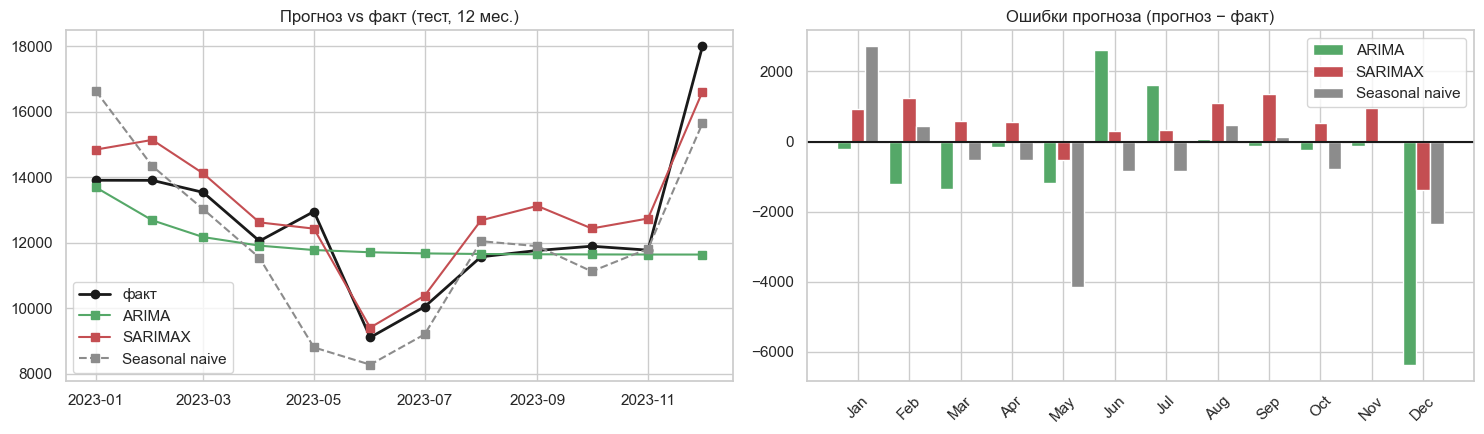

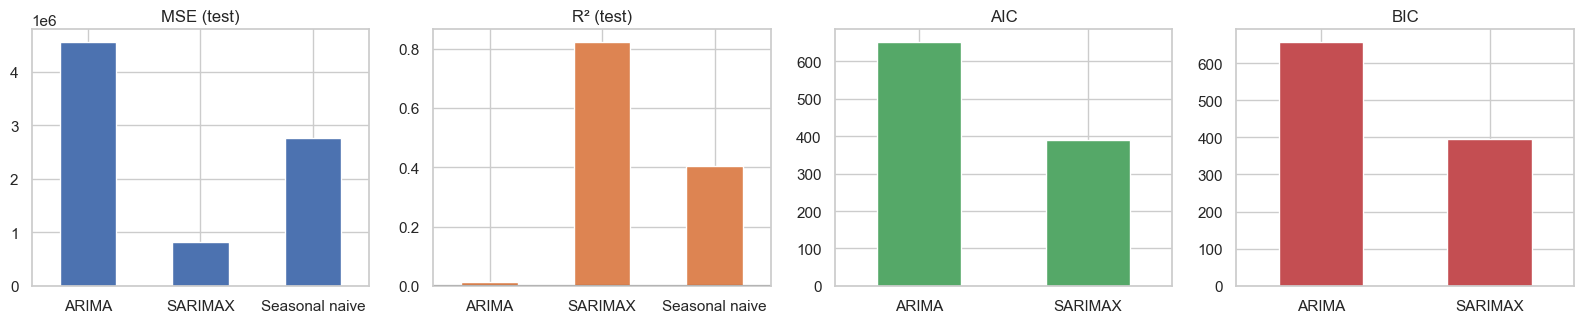

In [25]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].plot(y_te, c='k', marker='o', lw=2, label='факт')
for nm, c in [('ARIMA', 'C2'), ('SARIMAX', 'C3'), ('Seasonal naive', 'C7')]:
    axs[0].plot(pred[nm], marker='s', c=c, ls='--' if nm == 'Seasonal naive' else '-', label=nm)
axs[0].legend(); axs[0].set_title('Прогноз vs факт (тест, 12 мес.)')
for nm, c in [('ARIMA', 'C2'), ('SARIMAX', 'C3'), ('Seasonal naive', 'C7')]:
    axs[1].bar(np.arange(TEST) + {'ARIMA': -.27, 'SARIMAX': 0, 'Seasonal naive': .27}[nm], (pred[nm] - y_te).values, width=.26, color=c, label=nm)
axs[1].axhline(0, c='k'); axs[1].set_xticks(range(TEST)); axs[1].set_xticklabels(y_te.index.strftime('%b'), rotation=45)
axs[1].set_title('Ошибки прогноза (прогноз − факт)'); axs[1].legend()
plt.tight_layout(); plt.show()

# Сводная графика метрик
fig, axs = plt.subplots(1, 4, figsize=(16, 3.4))
tab[['MSE']].plot(kind='bar', ax=axs[0], legend=False, color='C0'); axs[0].set_title('MSE (test)')
tab[['R²']].plot(kind='bar', ax=axs[1], legend=False, color='C1'); axs[1].set_title('R² (test)'); axs[1].axhline(0, c='k')
ic[['AIC']].plot(kind='bar', ax=axs[2], legend=False, color='C2'); axs[2].set_title('AIC')
ic[['BIC']].plot(kind='bar', ax=axs[3], legend=False, color='C3'); axs[3].set_title('BIC')
for ax in axs: ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

### 2.3.3. Анализ остатков: нормальность, автокоррелированность, гомоскедастичность

In [26]:
# Остатки одношаговых предсказаний на train. Для SARIMAX отбрасываем первые 12 остатков (burn-in сезонной разности).
res_a = m_arima.resid.iloc[0:]
res_s = m_sarimax.resid.iloc[burn:]

def residual_tests(r, k_params, name):
    r = r.dropna()
    lb = acorr_ljungbox(r, lags=[6, 10], model_df=0, return_df=True)         # автокорреляция
    jb_stat, jb_p, skew, kurt = jarque_bera(r)                               # нормальность
    sh_p = stats.shapiro(r)[1]
    # Гомоскедастичность: (а) тест отношения дисперсий 2-й и 1-й половины (Голдфельд–Куандт-подобный, F-тест), (б) ARCH-LM
    h = len(r) // 2
    F = r.iloc[h:].var() / r.iloc[:h].var(); gq_p = 2 * min(stats.f.cdf(F, len(r) - h - 1, h - 1), 1 - stats.f.cdf(F, len(r) - h - 1, h - 1))
    arch_p = het_arch(r, nlags=2)[1]
    return {'Модель': name, 'N': len(r), 'Среднее остатков': r.mean(), 'СКО': r.std(),
            'Ljung-Box p (лаг 6)': lb['lb_pvalue'].iloc[0], 'Ljung-Box p (лаг 10)': lb['lb_pvalue'].iloc[1],
            'Jarque-Bera p': jb_p, 'Shapiro p': sh_p, 'Асимметрия': skew, 'Эксцесс': kurt,
            'F-тест дисперсий p': gq_p, 'ARCH-LM p': arch_p}

diag = pd.DataFrame([residual_tests(res_a, len(m_arima.params), 'ARIMA'),
                     residual_tests(res_s, len(m_sarimax.params), 'SARIMAX')]).set_index('Модель').T
display(diag)

# Правило интерпретации: p > 0.05 => H0 (нет автокорреляции / нормальность / гомоскедастичность) не отвергается
interp = pd.DataFrame({
    'Автокорреляция (LB, лаг 10)': ['нет (ОК)' if diag.loc['Ljung-Box p (лаг 10)', m] > .05 else 'есть (плохо)' for m in diag.columns],
    'Нормальность (Shapiro)': ['да (ОК)' if diag.loc['Shapiro p', m] > .05 else 'нет (плохо)' for m in diag.columns],
    'Гомоскедастичность (F-тест)': ['да (ОК)' if diag.loc['F-тест дисперсий p', m] > .05 else 'нет (плохо)' for m in diag.columns],
    'Гомоскедастичность (ARCH)': ['да (ОК)' if diag.loc['ARCH-LM p', m] > .05 else 'нет (плохо)' for m in diag.columns],
}, index=diag.columns)
display(interp)

Модель,ARIMA,SARIMAX
N,36.000,24.000
Среднее остатков,-2.669,1.982
СКО,"1,954.346",664.708
Ljung-Box p (лаг 6),0.296,0.438
Ljung-Box p (лаг 10),0.315,0.477
Jarque-Bera p,0.884,0.480
Shapiro p,0.188,0.277
Асимметрия,0.059,0.531
Эксцесс,3.389,2.416
F-тест дисперсий p,0.656,0.287


,"Автокорреляция (LB, лаг 10)",Нормальность (Shapiro),Гомоскедастичность (F-тест),Гомоскедастичность (ARCH)
Модель,,,,
ARIMA,нет (ОК),да (ОК),да (ОК),да (ОК)
SARIMAX,нет (ОК),да (ОК),да (ОК),да (ОК)


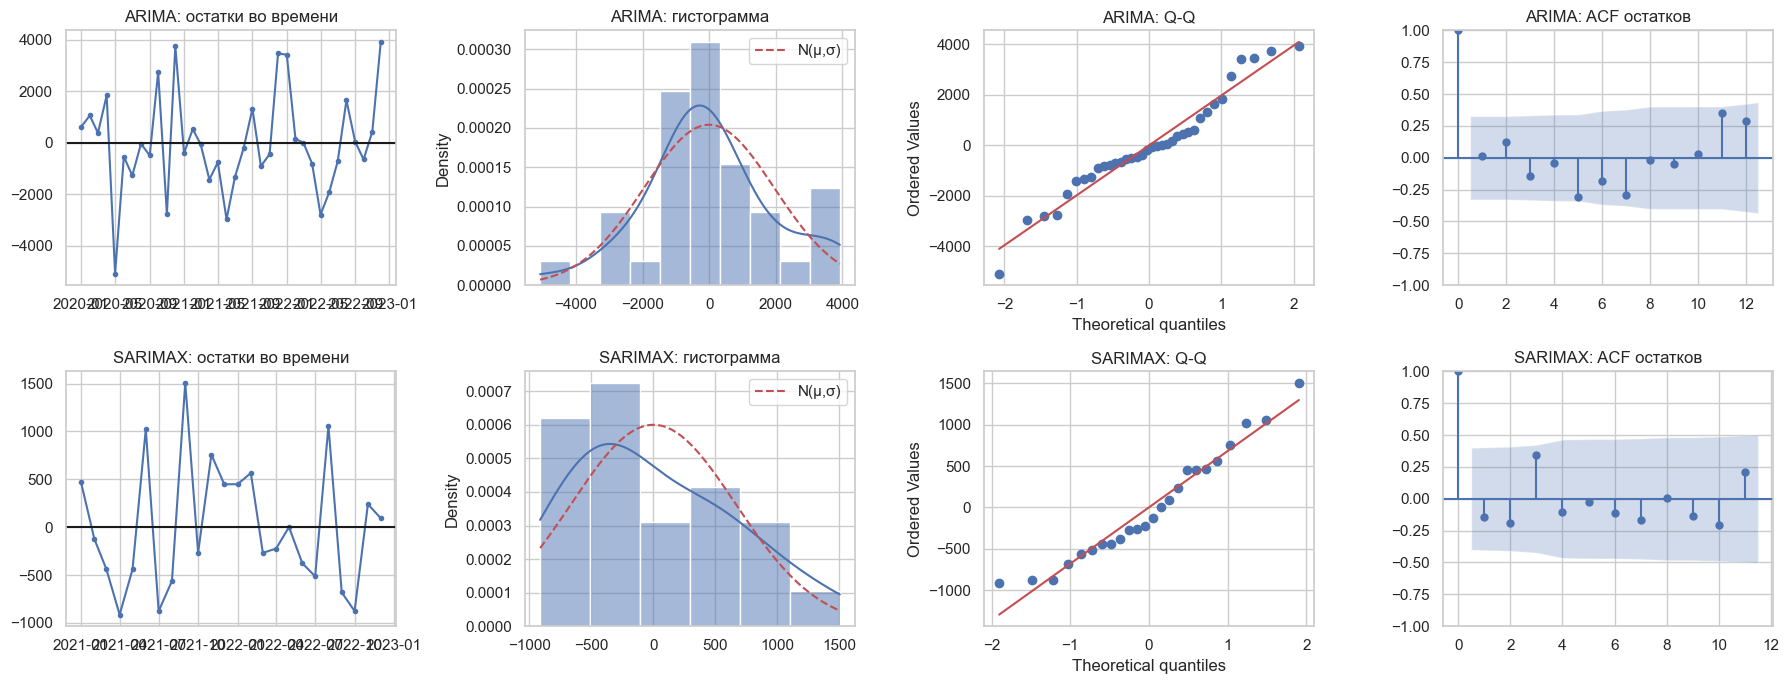

In [27]:
# Графики остатков: во времени, гистограмма с нормальной кривой, Q-Q, ACF
fig, axs = plt.subplots(2, 4, figsize=(18, 7))
for row, (nm, r) in enumerate([('ARIMA', res_a), ('SARIMAX', res_s)]):
    axs[row, 0].plot(r, marker='o', ms=3); axs[row, 0].axhline(0, c='k'); axs[row, 0].set_title(f'{nm}: остатки во времени')
    sns.histplot(r, kde=True, stat='density', ax=axs[row, 1])
    xs = np.linspace(r.min(), r.max(), 200); axs[row, 1].plot(xs, stats.norm.pdf(xs, r.mean(), r.std()), 'r--', label='N(μ,σ)')
    axs[row, 1].legend(); axs[row, 1].set_title(f'{nm}: гистограмма')
    stats.probplot(r, dist='norm', plot=axs[row, 2]); axs[row, 2].set_title(f'{nm}: Q-Q')
    plot_acf(r, lags=min(12, len(r) // 2 - 1), ax=axs[row, 3]); axs[row, 3].set_title(f'{nm}: ACF остатков')
plt.tight_layout(); plt.show()

### 2.3.4. Итоговая сводная таблица и выбор модели

In [28]:
final = pd.DataFrame({
    'MSE (test)': tab['MSE'][['ARIMA', 'SARIMAX']],
    'RMSE (test)': tab['RMSE'][['ARIMA', 'SARIMAX']],
    'R² (test)': tab['R²'][['ARIMA', 'SARIMAX']],
    'MAPE, % (test)': tab['MAPE, %'][['ARIMA', 'SARIMAX']],
    'AIC': ic['AIC'], 'BIC': ic['BIC'],
    'Горизонт с прием. качеством, мес.': pd.Series(HORIZON)[['ARIMA', 'SARIMAX']],
    'Остатки без автокорр.': interp['Автокорреляция (LB, лаг 10)'],
    'Остатки нормальны': interp['Нормальность (Shapiro)'],
    'Гомоскедастичность': interp['Гомоскедастичность (F-тест)'],
})
display(final.T)
print('Бенчмарк (Seasonal naive): MSE = %.0f, R² = %.3f' % (tab.loc['Seasonal naive', 'MSE'], tab.loc['Seasonal naive', 'R²']))

# Вклад экзогенных переменных в SARIMAX
ex = pd.DataFrame({'coef': m_sarimax.params[['Promotion']], 'p-value': m_sarimax.pvalues[['Promotion']]})
print('Коэффициент экзогенной переменной SARIMAX (эффект акции, ед. продаж):'); display(ex)

,ARIMA,SARIMAX
MSE (test),"4,565,244.439","815,176.384"
RMSE (test),"2,136.643",902.871
R² (test),0.013,0.824
"MAPE, % (test)",9.651,6.418
AIC,653.040,388.791
BIC,657.791,394.682
"Горизонт с прием. качеством, мес.",6,12
Остатки без автокорр.,нет (ОК),нет (ОК)
Остатки нормальны,да (ОК),да (ОК)
Гомоскедастичность,да (ОК),да (ОК)


Бенчмарк (Seasonal naive): MSE = 2757115, R² = 0.404
Коэффициент экзогенной переменной SARIMAX (эффект акции, ед. продаж):


,coef,p-value
Promotion,"2,624.566",0.000


## Аналитические выводы по этапу 2.3

**Метрики на тесте (12 месяцев):**

| Модель | MSE | RMSE | R² | MAPE | AIC | BIC |
|---|---|---|---|---|---|---|
| ARIMA(1,0,0) | 4.57·10⁶ | 2 137 | 0.01 | 9.7 % | 653.0 | 657.8 |
| SARIMAX(0,0,1)(0,1,1)₁₂ + Promotion | 0.82·10⁶ | 903 | 0.82 | 6.4 % | 388.8 | 394.7 |
| Seasonal naive (бенчмарк) | 2.76·10⁶ | 1 660 | 0.40 | 8.8 % | — | — |

- **Точность.** MSE SARIMAX в ≈ 5.6 раза ниже, чем у ARIMA; R² = 0.82 против 0.01 (ARIMA фактически не лучше константного прогноза). SARIMAX также заметно лучше сезонного наивного бенчмарка (R² 0.82 против 0.40) — часть выигрыша даёт учёт акции (в мае 2023 акция, а в 2022 её не было). Самая показательная точка — декабрь 2023: факт 17 996, SARIMAX 16 611 (−7.7 %), ARIMA 11 635 (−35 %).
- **Информационные критерии.** AIC и BIC существенно ниже у SARIMAX. Формально сравнивать их нужно осторожно: SARIMAX из-за Δ12 использует в правдоподобии 24 наблюдения, ARIMA — 36. Поэтому дополнительно посчитаны AIC*/BIC* на одних и тех же 24 точках: 431.9 / 435.4 у ARIMA против 389.1 / 394.9 у SARIMAX — вывод тот же (разница > 40 единиц).
- **Остатки (p > 0.05 означает «гипотеза не отвергается»).** У обеих моделей: нет автокорреляции (Ljung–Box, лаг 10: p = 0.32 у ARIMA и 0.48 у SARIMAX), нормальность не отвергается (Шапиро: 0.19 / 0.28; Жарка–Бера: 0.88 / 0.48), дисперсия постоянна (F-тест: 0.66 / 0.29; ARCH-LM: 0.45 / 0.53), среднее остатков ≈ 0. Разница в **масштабе**: СКО остатков 1 954 у ARIMA против 665 у SARIMAX. «Белые» остатки ARIMA не означают хороший прогноз: модель просто не использует сезонную структуру, а при 24–36 точках тесты обладают низкой мощностью, так что «не отвергнуто» не равно «доказано».
- **Итог.** По всем критериям (MSE, R², MAPE, AIC, BIC, горизонт 12 против 6 месяцев, масштаб остатков) **предпочтительна SARIMAX**. ARIMA без сезонности для ряда с сильной (Fs ≈ 0.83) годовой периодичностью неприменима для горизонтов длиннее 2–3 месяцев.
- **Оговорка:** оценка качества основана на одном тестовом окне из 12 точек, поэтому R² = 0.82 следует считать ориентировочным (доверительный интервал оценки широк).

# 2.4. Документирование и интерпретация

Каждый шаг ноутбука сопровождён комментариями в коде и текстовыми пояснениями; после этапов 2.1, 2.2, 2.3 приведены аналитические выводы, ниже — общий вывод по работе и ограничения.

## Общий вывод

1. **EDA.** Ряд стационарен относительно константы, без значимого тренда, с одной выраженной периодичностью — **12 месяцев**; три метода (декомпозиция/STL, FFT, вейвлеты) подтверждают это независимо и дополняют друг друга: декомпозиция даёт сезонный профиль, FFT — статистически обоснованный период, вейвлеты — локализацию по времени и контроль её стабильности.
2. **Моделирование.** Параметры ARIMA и SARIMAX выбраны на основе EDA (d = 0, s = 12, D = 1, `Promotion` как экзогенная переменная) и по AIC на обучающей выборке без использования теста. Модели с вырожденными корнями исключены.
3. **Качество.** SARIMAX(0,0,1)(0,1,1)₁₂ + константа + `Promotion` — предпочтительная модель: R² = 0.82 и MAPE ≈ 6.4 % на 12-месячном горизонте, приемлемое качество на всём проверяемом горизонте, остатки удовлетворяют допущениям.
4. **Практический вывод.** Акция в среднем добавляет ≈ 2.6 тыс. ед. продаж в месяц; декабрь — главный сезонный пик; прогноз устойчив на горизонте до 12 месяцев.

**Ограничения и что можно улучшить.** Короткий ряд (48 точек) ограничивает точность оценок и мощность тестов; тестовая выборка — один год; будущие значения `Promotion` надо задавать по плану акций. С большим объёмом данных стоит использовать скользящую (rolling-origin) кросс-валидацию, сравнить с ETS/Prophet и моделями с регрессорами, а также проверить гипотезу о росте амплитуды сезонности (мультипликативная структура).